<a href="https://colab.research.google.com/github/Ben-069/DataManPy/blob/main/NBIPAR_Dengean%26Ortega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#DETERMINANTS OF NBI IN RURAL PARAGUAY - Evidence of 2022 Data
**Authors:** Benito Ortega Torres M.Sc ; Rosa Marilin Dengean Paiva M.Sc
**Class:** Data Management, fall 2026
**Professor:** Adam Okulicz-Kozaryn, Phd

##ABSTRACT
Agricultural activity and household deprivation intersect within territories shaped by demographic composition, land tenure, and unequal development opportunities. This study examines district-level associations between agricultural activity composition and unmet basic needs in subsistence capacity in Paraguay, incorporating household composition and land-tenure indicators. Data from the 2022 National Population and Housing Census were linked to the 2022 National Agricultural Census. Descriptive statistics and Pearson and Spearman correlations were calculated using available observations, followed by an ordinary least squares regression with HC3 robust standard errors for 230 districts. Bivariate results indicated a negative association between crop-only farm shares and deprivation and a positive association for livestock-only farm shares. Neither agricultural indicator remained statistically significant after adjustment for the included household and tenure variables. Higher shares of incomplete nuclear households were associated with higher deprivation, whereas owned and rented land-tenure shares were associated with lower deprivation. The model accounted for 36.9% of observed district-level variation. These findings suggest that agricultural composition should be interpreted alongside household and territorial conditions rather than as an isolated explanation of deprivation. Cross-sectional measurement, incomplete agricultural reporting, potential spatial dependence, and the aggregate nature of the data limit causal and household-level interpretation.

Keywords: Paraguay; unmet basic needs; agricultural composition; household structure; land tenure; territorial inequality.

##INTRODUCTION
Agricultural production can generate economic growth without distributing its benefits evenly across households and territories. In Latin America, research has repeatedly connected rural deprivation to unequal access to productive resources, employment, and institutional support. Kay (2006) emphasizes that poverty is reproduced through unequal distributions of resources and power, while Bebbington (1999) situates livelihood possibilities within access to assets and the capabilities to use them. These perspectives suggest that the relationship between agriculture and well-being depends on the conditions under which people participate in productive activities, rather than on production alone.

Paraguay provides an important setting for examining these relationships. Research on its agrarian transformation documents persistent land concentration and differentiated opportunities within expanding agricultural markets. Pereira Cardozo and Solís (2024), comparing the 2008 and 2022 agricultural censuses, identify continuing concentration in the agrarian structure. Wesz Junior (2022) examines how productive and commercial relationships within the soybean sector reshape smallholder opportunities. Together, these studies highlight why agricultural activity must be considered alongside the social organization of production and access to resources.

The social implications of agricultural development are nevertheless heterogeneous. Cardozo et al. (2016) document different livelihood responses to soybean expansion among peasant and Indigenous communities in eastern Paraguay. Elsewhere in the region, Weinhold et al. (2013) find that soybean expansion in the Brazilian Amazon is associated with improvements in some poverty and income measures alongside increased inequality. These findings caution against assigning a uniform social effect to an agricultural activity or interpreting improvements in one indicator as evidence of broadly inclusive development.

A territorial perspective provides a useful framework for investigating this variation. Berdegué et al. (2015) emphasize the interaction of structures, institutions, and coalitions in shaping Latin American rural development. Modrego and Berdegué (2015) demonstrate that national development trends conceal substantial differences among local administrative units. District-level analysis can therefore reveal associations that national averages obscure, while also requiring attention to the demographic and institutional conditions that vary across places.

This study asks: How are the district-level shares of exclusively crop-producing and exclusively livestock-producing farms associated with household NBI in subsistence capacity, before and after adjustment for selected household composition and land-tenure characteristics? It links Paraguay’s 2022 agricultural and population census tables through a documented geographic harmonization process. The analysis combines descriptive statistics, bivariate correlations, and an exploratory multiple regression.

The study contributes a reproducible territorial analysis that distinguishes agricultural activity composition from household deprivation. Its indicators describe the distribution of establishments across activities; they do not directly identify family farming, agricultural productivity, or the circumstances of individual farming households. By examining agricultural indicators together with selected household and tenure characteristics, the study evaluates whether their bivariate associations persist in a broader specification. The objective is to identify patterns that merit further investigation, rather than to estimate causal effects.

##LIMITATIONS
Several limitations should guide interpretation of the findings.

First, the study uses cross-sectional data from 2022. The analysis cannot establish temporal ordering or determine whether agricultural composition influences deprivation, whether deprivation shapes productive choices, or whether both reflect other territorial conditions. Adjustment for the included variables does not resolve these possibilities.

Second, the data are aggregated at the district level. Agricultural establishments are not linked to individual households, and the deprivation measure includes households generally rather than exclusively farming households. Consequently, the findings cannot establish whether households operating crop-only or livestock-only farms experience different deprivation levels. District associations must not be interpreted as individual or household effects.

Third, analytical coverage varies across variables. Household and tenure indicators cover 263 geographic units, while crop-only and livestock-only percentages are available for 230 and 245 districts, respectively. The regression includes 230 complete cases. If excluded districts differ systematically in productive structure, urbanization, or deprivation, complete-case estimates may not describe the broader set of districts adequately.

Fourth, agricultural reporting symbols remain a substantive data limitation. Original blanks and guions were documented and provisionally represented as missing values. Their interpretation requires confirmation from the source. If guions represent an absence of activity rather than unavailable information, the current treatment would exclude valid zero observations and could affect descriptive statistics, correlations, and regression estimates. The results should remain preliminary until this issue is resolved.

Fifth, the available agricultural indicators measure the percentage of farms in broad activity categories. They do not directly measure family farming, farm size, land concentration, production value, employment intensity, or commercialization. Similarly, tenure classifications do not necessarily establish secure legal ownership or effective control over productive land.

#DATA MANAGEMENT

## DV: UNSATISFIED BASIC NEED INDEX, 2022

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
sociopy2022 = pd.ExcelFile("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download")
agrcensus2022= pd.ExcelFile("https://docs.google.com/uc?id=1n8d_1lubOtPqiwjadoadYDMWuLBaI__b&export=download")

In [ ]:
print("Hojas del archivo 1:", sociopy2022.sheet_names)
print("Hojas del archivo 2:", agrcensus2022.sheet_names)

Hojas del archivo 1: ['Cuadro 1', 'Cuadro 2', 'Cuadro 3', 'Cuadro 4']
Hojas del archivo 2: ['PEDIDO']


Using data provided by the National Institute of Statistics, this first section covers cleaning and obtaining the main dependendt variable for this study , (Unsatisfied Basic Need Index, subsistence capacity 2022). The main challenges with this dataset, are that due to formatting, it has a lot of junk and empty cells in the header of the original file

In [ ]:
sociopy2022 = pd.read_excel("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download",sheet_name="Cuadro 4",header=None)

agrcensus2022 = pd.read_excel("https://docs.google.com/uc?id=1n8d_1lubOtPqiwjadoadYDMWuLBaI__b&export=download",sheet_name="PEDIDO",header=None)

In [ ]:
sociopy2022.head(16)

,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Cuadro 4,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Paraguay. Hogares particulares por Necesidades...,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Departamento y distrito,Total de hogares,Hogares con Necesidades Básicas Insatisfechas ...,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,Al menos una NBI,NBI en,NaN,NaN,NaN


In [ ]:
"Dimensiones de NBI:", sociopy2022.shape
"Dimensiones de CAN:", agrcensus2022.shape

('Dimensiones de CAN:', (311, 17))

In [ ]:
#Creating some meaningful names
nbi = sociopy2022.iloc[12:, 1:8].copy()
nbi.columns = ["name","total_homes","homeswithonenbi","homesnbihouse","homesnbisanity","homesnbieduc","homesnbisubs"]
nbi.head(10)

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
12,Total País,1770755,501781,113025,184957,186865,147132
13,Asunción,133600,23296,5789,7383,6623,6746
14,Concepción,56837,19484,4635,7093,7269,6352
15,Concepción,19196,5678,1603,1999,1797,1575
16,Belén,3015,963,228,252,357,341
17,Horqueta,11355,3409,700,878,1427,1242
18,Loreto,3811,1261,283,473,409,412
19,San Carlos del Apa,270,129,31,49,43,30
20,San Lázaro,3068,1347,389,811,426,229
21,Yby Yaú,5561,2150,499,840,1043,723


In [ ]:
nbi.tail(10)

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
284,Mariscal José Félix Estigarribia,3412,2356,688,1758,884,1036
285,Filadelfia,6096,5006,547,4715,1038,562
286,Loma Plata,6257,5764,564,5642,860,638
287,Boquerón,4633,3971,726,3677,863,766
288,Alto Paraguay,5199,3272,802,2280,1028,853
289,Fuerte Olimpo,1320,800,213,558,230,169
290,Puerto Casado,1689,1152,281,918,352,349
291,Bahía Negra,850,514,129,323,182,97
292,Carmelo Peralta,1340,806,179,481,264,238
293,Fuente: INE. Censo Nacional de Población y Viv...,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
nbi = nbi.dropna(subset=["total_homes"]).copy()
nbi.tail(10)

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs
283,Boquerón,20398,17097,2525,15792,3645,3002
284,Mariscal José Félix Estigarribia,3412,2356,688,1758,884,1036
285,Filadelfia,6096,5006,547,4715,1038,562
286,Loma Plata,6257,5764,564,5642,860,638
287,Boquerón,4633,3971,726,3677,863,766
288,Alto Paraguay,5199,3272,802,2280,1028,853
289,Fuerte Olimpo,1320,800,213,558,230,169
290,Puerto Casado,1689,1152,281,918,352,349
291,Bahía Negra,850,514,129,323,182,97
292,Carmelo Peralta,1340,806,179,481,264,238


In [ ]:
import openpyxl
import requests
import io
#code suggested by gemini ai
# Download the file content from the URL
url = "https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download"
response = requests.get(url)

# Load the workbook from the in-memory bytes object
libro = openpyxl.load_workbook(io.BytesIO(response.content), data_only=True)
hoja = libro["Cuadro 4"]

nbi["bold_name"] = [
    hoja.cell(row=indice + 1, column=2).font.bold == True
    for indice in nbi.index
    ]

display(nbi[["name", "total_homes", "bold_name"]].head(20))

,name,total_homes,bold_name
12,Total País,1770755,True
13,Asunción,133600,True
14,Concepción,56837,True
15,Concepción,19196,False
16,Belén,3015,False
17,Horqueta,11355,False
18,Loreto,3811,False
19,San Carlos del Apa,270,False
20,San Lázaro,3068,False
21,Yby Yaú,5561,False


In [ ]:
#since we dont need departament and they are in bold, I am using that "bold" criteria to get rid of those subtotals and totals.
nbi["department"] = nbi["name"].where(nbi["bold_name"])
nbi["department"] = nbi["department"].ffill()
nbi.head(10)

,name,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs,bold_name,department
12,Total País,1770755,501781,113025,184957,186865,147132,True,Total País
13,Asunción,133600,23296,5789,7383,6623,6746,True,Asunción
14,Concepción,56837,19484,4635,7093,7269,6352,True,Concepción
15,Concepción,19196,5678,1603,1999,1797,1575,False,Concepción
16,Belén,3015,963,228,252,357,341,False,Concepción
17,Horqueta,11355,3409,700,878,1427,1242,False,Concepción
18,Loreto,3811,1261,283,473,409,412,False,Concepción
19,San Carlos del Apa,270,129,31,49,43,30,False,Concepción
20,San Lázaro,3068,1347,389,811,426,229,False,Concepción
21,Yby Yaú,5561,2150,499,840,1043,723,False,Concepción


In [ ]:
es_distrito = nbi["bold_name"] == False
es_asuncion = nbi["name"] == "Asunción"
nbi_districts = nbi[es_distrito | es_asuncion].copy()
#to make merge easier I changed the names of the colums names to new, meaningful ones so merge is easier
nbi_districts = nbi_districts.rename(columns={"name": "district"})
nbi_districts[["department", "district", "total_homes"]].head(10)


,department,district,total_homes
13,Asunción,Asunción,133600
15,Concepción,Concepción,19196
16,Concepción,Belén,3015
17,Concepción,Horqueta,11355
18,Concepción,Loreto,3811
19,Concepción,San Carlos del Apa,270
20,Concepción,San Lázaro,3068
21,Concepción,Yby Yaú,5561
22,Concepción,Azote’y,1821
23,Concepción,Sargento José Félix López,1656


In [ ]:
#This is just for check for duplicates
duplicados = nbi_districts.duplicated(subset=["department", "district"], keep=False)
nbi_districts.loc[duplicados, ["department", "district"]]

,department,district


In [ ]:
#This is to turn into numbers any possible data that could be potentially text
numeric_columns = ["total_homes","homeswithonenbi","homesnbihouse","homesnbisanity","homesnbieduc","homesnbisubs"]
for column in numeric_columns:nbi_districts[column] = pd.to_numeric(nbi_districts[column],errors="raise")
nbi_districts[numeric_columns].dtypes



,0
total_homes,int64
homeswithonenbi,int64
homesnbihouse,int64
homesnbisanity,int64
homesnbieduc,int64
homesnbisubs,int64


In [ ]:
#Since I am going to use percentages for my futher analysis I am converting them to %
nbi_districts["nbi_subsistence_pct"] = (nbi_districts["homesnbisubs"]/ nbi_districts["total_homes"]) * 100
nbi_districts[["department","district","total_homes","homesnbisubs","nbi_subsistence_pct"]].head(10)

,department,district,total_homes,homesnbisubs,nbi_subsistence_pct
13,Asunción,Asunción,133600,6746,5.049401
15,Concepción,Concepción,19196,1575,8.204834
16,Concepción,Belén,3015,341,11.310116
17,Concepción,Horqueta,11355,1242,10.937913
18,Concepción,Loreto,3811,412,10.810811
19,Concepción,San Carlos del Apa,270,30,11.111111
20,Concepción,San Lázaro,3068,229,7.464146
21,Concepción,Yby Yaú,5561,723,13.001259
22,Concepción,Azote’y,1821,328,18.012081
23,Concepción,Sargento José Félix López,1656,224,13.526570


In [ ]:
#In case I need to use this again, I doesn't hurt to dowload one copy
#nbi_districts.to_csv("NBI_districts_2022.csv",index=False,encoding="utf-8-sig")

# SOCIO DEMOGRAPHIC DATA - INE

##HOUSELHOLD COMPOSITION

In this second subsection I am going to clean household composition data for further analysis, since they are going to be useful as controls, and for descriptive analysis. This data was extracted from a secondary book in the 2022 census data file provided by the National Institute of Statistics.

In [ ]:
household_var2022 = pd.read_excel("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download",sheet_name="Cuadro 1",header=None)
household_var2022.head(10)

,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Cuadro 1,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Paraguay. Hogares particulares por tipo de hog...,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Departamento y distrito,Total de hogares,Tipo de Hogar,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,Unipersonal,Nuclear completo,Nuclear incompleto,Extendido,Compuesto


In [ ]:
household_var2022.shape

(293, 8)

The raw data shows to have 293 rows and 8 columns which has the same problems as the first file: several rows with junk text that in the original file are headers and also empty spaces. Therefore, the procedure would be very similar, droping useless rows, normalize names, subseting only municipalities and their values.

In [ ]:
#first I assigned them meaningful names
#note that column "name" refers to the district name that we are going to change to "distric" so merge can be as easy as eating an apple"
fam_type = household_var2022.iloc[12:, 1:8].copy()
fam_type.columns = ["name","total_homes","uni_home","comp_home","incomp_home","ext_home","compound_home"]
fam_type.head(10)

,name,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home
12,Asunción,133600,24372,48768,14652,40834,4974
13,Concepción,56837,7638,24617,7133,16401,1048
14,Concepción,19196,2438,7567,2345,6363,483
15,Belén,3015,405,1374,365,840,31
16,Horqueta,11355,1599,5204,1404,3019,129
17,Loreto,3811,468,1764,505,1044,30
18,San Carlos del Apa,270,60,120,29,56,5
19,San Lázaro,3068,470,1317,321,901,59
20,Yby Yaú,5561,727,2540,698,1484,112
21,Azote’y,1821,237,820,277,461,26


In [ ]:
fam_type.tail(3)


,name,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home
290,Bahía Negra,850,175,346,82,155,92
291,Carmelo Peralta,1340,238,546,216,281,59
292,Fuente: INE. Censo Nacional de Población y Viv...,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#I am just reapeating the process of identifying the departament names and getting rid of them using the their format "bold"
fam_type = fam_type.dropna(subset=["total_homes"]).copy()
household_sheet = libro["Cuadro 1"]
fam_type["bold_name"] = [household_sheet.cell(row=index + 1, column=2 ).font.bold == True for index in fam_type.index]


In [ ]:
fam_type[["name", "total_homes", "bold_name"]].head(16)

,name,total_homes,bold_name
12,Asunción,133600,True
13,Concepción,56837,True
14,Concepción,19196,False
15,Belén,3015,False
16,Horqueta,11355,False
17,Loreto,3811,False
18,San Carlos del Apa,270,False
19,San Lázaro,3068,False
20,Yby Yaú,5561,False
21,Azote’y,1821,False


In [ ]:
#We want just districts and also change some colums names for merging
fam_type["department"] = fam_type["name"].where(fam_type["bold_name"])
fam_type["department"] = fam_type["department"].ffill()
is_district = ~fam_type["bold_name"]
is_asuncion = fam_type["name"] == "Asunción"
fam_districts = fam_type.loc[is_district | is_asuncion].copy()
fam_districts = fam_districts.rename(columns={"name": "district"})
fam_districts.head(10)

,district,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home,bold_name,department
12,Asunción,133600,24372,48768,14652,40834,4974,True,Asunción
14,Concepción,19196,2438,7567,2345,6363,483,False,Concepción
15,Belén,3015,405,1374,365,840,31,False,Concepción
16,Horqueta,11355,1599,5204,1404,3019,129,False,Concepción
17,Loreto,3811,468,1764,505,1044,30,False,Concepción
18,San Carlos del Apa,270,60,120,29,56,5,False,Concepción
19,San Lázaro,3068,470,1317,321,901,59,False,Concepción
20,Yby Yaú,5561,727,2540,698,1484,112,False,Concepción
21,Azote’y,1821,237,820,277,461,26,False,Concepción
22,Sargento José Félix López,1656,237,822,187,365,45,False,Concepción


In [ ]:
fam_districts[["department", "district", "total_homes"]].head(10)

,department,district,total_homes
12,Asunción,Asunción,133600
14,Concepción,Concepción,19196
15,Concepción,Belén,3015
16,Concepción,Horqueta,11355
17,Concepción,Loreto,3811
18,Concepción,San Carlos del Apa,270
19,Concepción,San Lázaro,3068
20,Concepción,Yby Yaú,5561
21,Concepción,Azote’y,1821
22,Concepción,Sargento José Félix López,1656


In [ ]:
#check for data type and mumeric values
family_columns = ["uni_home","comp_home","incomp_home","ext_home","compound_home"]
for column in ["total_homes"] + family_columns:fam_districts[column] = pd.to_numeric(fam_districts[column],errors="raise")
#print("Missing values:")
fam_districts[["total_homes"] + family_columns].isna().sum()

,0
total_homes,0
uni_home,0
comp_home,0
incomp_home,0
ext_home,0
compound_home,0


In [ ]:
#we also need to know the percentage of homes for our control variables so lets convert it to %
family_pct_columns = []
for column in family_columns:
    new_column = "pct_" + column
    fam_districts[new_column] = (fam_districts[column] / fam_districts["total_homes"]) * 100
    family_pct_columns.append(new_column)

fam_districts[["department", "district"] + family_pct_columns].head(10)

,department,district,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home
12,Asunción,Asunción,18.242515,36.502994,10.967066,30.564371,3.723054
14,Concepción,Concepción,12.700563,39.419671,12.216087,33.147531,2.516149
15,Concepción,Belén,13.432836,45.572139,12.106136,27.860697,1.028192
16,Concepción,Horqueta,14.081902,45.830031,12.364597,26.587406,1.136063
17,Concepción,Loreto,12.280241,46.287064,13.251115,27.394385,0.787195
18,Concepción,San Carlos del Apa,22.222222,44.444444,10.740741,20.740741,1.851852
19,Concepción,San Lázaro,15.319426,42.926988,10.462842,29.367666,1.923077
20,Concepción,Yby Yaú,13.073188,45.675238,12.551699,26.685848,2.014026
21,Concepción,Azote’y,13.014827,45.030203,15.211422,25.315761,1.427787
22,Concepción,Sargento José Félix López,14.311594,49.637681,11.292271,22.041063,2.717391


In [ ]:
import unicodedata

def normalize_name(text):
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    text = " ".join(text.split())
    return text

fam_districts["department_key"] = (fam_districts["department"].apply(normalize_name))
fam_districts["district_key"] = (fam_districts["district"].apply(normalize_name))
fam_districts.duplicated(subset=["department_key", "district_key"]).sum()
#This was particulatly important consideron that most of the data contained spanish caracters, so I had to normalize them

np.int64(0)

In [ ]:
fam_districts.head(10)

,district,total_homes,uni_home,comp_home,incomp_home,ext_home,compound_home,bold_name,department,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home,department_key,district_key
12,Asunción,133600,24372,48768,14652,40834,4974,True,Asunción,18.242515,36.502994,10.967066,30.564371,3.723054,asuncion,asuncion
14,Concepción,19196,2438,7567,2345,6363,483,False,Concepción,12.700563,39.419671,12.216087,33.147531,2.516149,concepcion,concepcion
15,Belén,3015,405,1374,365,840,31,False,Concepción,13.432836,45.572139,12.106136,27.860697,1.028192,concepcion,belen
16,Horqueta,11355,1599,5204,1404,3019,129,False,Concepción,14.081902,45.830031,12.364597,26.587406,1.136063,concepcion,horqueta
17,Loreto,3811,468,1764,505,1044,30,False,Concepción,12.280241,46.287064,13.251115,27.394385,0.787195,concepcion,loreto
18,San Carlos del Apa,270,60,120,29,56,5,False,Concepción,22.222222,44.444444,10.740741,20.740741,1.851852,concepcion,san carlos del apa
19,San Lázaro,3068,470,1317,321,901,59,False,Concepción,15.319426,42.926988,10.462842,29.367666,1.923077,concepcion,san lazaro
20,Yby Yaú,5561,727,2540,698,1484,112,False,Concepción,13.073188,45.675238,12.551699,26.685848,2.014026,concepcion,yby yau
21,Azote’y,1821,237,820,277,461,26,False,Concepción,13.014827,45.030203,15.211422,25.315761,1.427787,concepcion,azote'y
22,Sargento José Félix López,1656,237,822,187,365,45,False,Concepción,14.311594,49.637681,11.292271,22.041063,2.717391,concepcion,sargento jose felix lopez


In [ ]:
keys = ["department_key", "district_key"]
family_to_merge = fam_districts[ keys + ["total_homes"] + family_columns + family_pct_columns ].copy()
family_to_merge = family_to_merge.rename( columns={"total_homes": "total_homes_family"})

In [ ]:
family_to_merge.head(10)

,department_key,district_key,total_homes_family,uni_home,comp_home,incomp_home,ext_home,compound_home,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home
12,asuncion,asuncion,133600,24372,48768,14652,40834,4974,18.242515,36.502994,10.967066,30.564371,3.723054
14,concepcion,concepcion,19196,2438,7567,2345,6363,483,12.700563,39.419671,12.216087,33.147531,2.516149
15,concepcion,belen,3015,405,1374,365,840,31,13.432836,45.572139,12.106136,27.860697,1.028192
16,concepcion,horqueta,11355,1599,5204,1404,3019,129,14.081902,45.830031,12.364597,26.587406,1.136063
17,concepcion,loreto,3811,468,1764,505,1044,30,12.280241,46.287064,13.251115,27.394385,0.787195
18,concepcion,san carlos del apa,270,60,120,29,56,5,22.222222,44.444444,10.740741,20.740741,1.851852
19,concepcion,san lazaro,3068,470,1317,321,901,59,15.319426,42.926988,10.462842,29.367666,1.923077
20,concepcion,yby yau,5561,727,2540,698,1484,112,13.073188,45.675238,12.551699,26.685848,2.014026
21,concepcion,azote'y,1821,237,820,277,461,26,13.014827,45.030203,15.211422,25.315761,1.427787
22,concepcion,sargento jose felix lopez,1656,237,822,187,365,45,14.311594,49.637681,11.292271,22.041063,2.717391


In [ ]:
# Define 'analysis' if it hasn't been defined yet, using nbi_districts as the base
if 'analysis' not in globals():
    analysis = nbi_districts.copy()

# Ensure the merge keys exist in 'analysis'
if "department_key" not in analysis.columns:
    analysis["department_key"] = analysis["department"].apply(normalize_name)
if "district_key" not in analysis.columns:
    analysis["district_key"] = analysis["district"].apply(normalize_name)

analysis_family = analysis.merge(family_to_merge, on=keys, how="left", validate="one_to_one", indicator="family_match")
display(analysis_family["family_match"].value_counts().to_frame("units"))

,units
family_match,
both,263
left_only,0
right_only,0


In [ ]:
analysis_family.head(20)

,district,total_homes,homeswithonenbi,homesnbihouse,homesnbisanity,homesnbieduc,homesnbisubs,bold_name,department,nbi_subsistence_pct,...,comp_home,incomp_home,ext_home,compound_home,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home,family_match
0,Asunción,133600,23296,5789,7383,6623,6746,True,Asunción,5.049401,...,48768,14652,40834,4974,18.242515,36.502994,10.967066,30.564371,3.723054,both
1,Concepción,19196,5678,1603,1999,1797,1575,False,Concepción,8.204834,...,7567,2345,6363,483,12.700563,39.419671,12.216087,33.147531,2.516149,both
2,Belén,3015,963,228,252,357,341,False,Concepción,11.310116,...,1374,365,840,31,13.432836,45.572139,12.106136,27.860697,1.028192,both
3,Horqueta,11355,3409,700,878,1427,1242,False,Concepción,10.937913,...,5204,1404,3019,129,14.081902,45.830031,12.364597,26.587406,1.136063,both
4,Loreto,3811,1261,283,473,409,412,False,Concepción,10.810811,...,1764,505,1044,30,12.280241,46.287064,13.251115,27.394385,0.787195,both
5,San Carlos del Apa,270,129,31,49,43,30,False,Concepción,11.111111,...,120,29,56,5,22.222222,44.444444,10.740741,20.740741,1.851852,both
6,San Lázaro,3068,1347,389,811,426,229,False,Concepción,7.464146,...,1317,321,901,59,15.319426,42.926988,10.462842,29.367666,1.923077,both
7,Yby Yaú,5561,2150,499,840,1043,723,False,Concepción,13.001259,...,2540,698,1484,112,13.073188,45.675238,12.551699,26.685848,2.014026,both
8,Azote’y,1821,702,213,182,318,328,False,Concepción,18.012081,...,820,277,461,26,13.014827,45.030203,15.211422,25.315761,1.427787,both
9,Sargento José Félix López,1656,787,175,404,301,224,False,Concepción,13.526570,...,822,187,365,45,14.311594,49.637681,11.292271,22.041063,2.717391,both


In [ ]:
#We are going yo need
family_columns = [
    "uni_home",
    "comp_home",
    "incomp_home",
    "ext_home",
    "compound_home"
]

family_pct_columns = []

analysis_family["total_homes"] = pd.to_numeric(
    analysis_family["total_homes"],
    errors="raise"
)

for column in family_columns:
    analysis_family[column] = pd.to_numeric(
        analysis_family[column],
        errors="raise"
    )

    new_column = "pct_" + column

    analysis_family[new_column] = (
        analysis_family[column]
        / analysis_family["total_homes"]
    ) * 100

    family_pct_columns.append(new_column)

In [ ]:
analysis_family[
    [
        "department",
        "district",
        "pct_compound_home",
        "nbi_subsistence_pct"
    ]
].nlargest(6, "pct_compound_home")

,department,district,pct_compound_home,nbi_subsistence_pct
251,Presidente Hayes,Teniente Esteban Martínez,18.383312,20.078227
261,Alto Paraguay,Bahía Negra,10.823529,11.411765
220,Ñeembucú,Villa Franca,8.630952,6.547619
259,Alto Paraguay,Fuerte Olimpo,6.212121,12.803030
252,Presidente Hayes,General José María Bruguez,5.941846,20.606827
253,Presidente Hayes,Campo Aceval,5.841121,7.651869


In [ ]:
analysis_family.columns

Index(['district', 'total_homes', 'homeswithonenbi', 'homesnbihouse',
       'homesnbisanity', 'homesnbieduc', 'homesnbisubs', 'bold_name',
       'department', 'nbi_subsistence_pct', 'department_key', 'district_key',
       'total_homes_family', 'uni_home', 'comp_home', 'incomp_home',
       'ext_home', 'compound_home', 'pct_uni_home', 'pct_comp_home',
       'pct_incomp_home', 'pct_ext_home', 'pct_compound_home', 'family_match'],
      dtype='object')

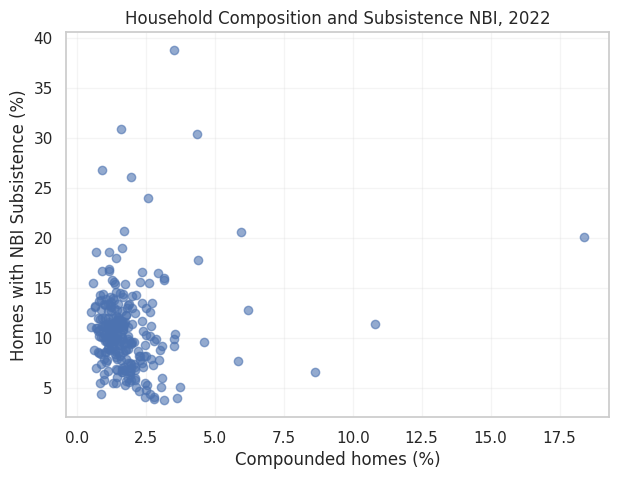

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    analysis_family["pct_compound_home"],
    analysis_family["nbi_subsistence_pct"],
    alpha=0.6
)

plt.xlabel("Compounded homes (%)")
plt.ylabel("Homes with NBI Subsistence (%)")
plt.title("Household Composition and Subsistence NBI, 2022")
plt.grid(alpha=0.2)

plt.show()

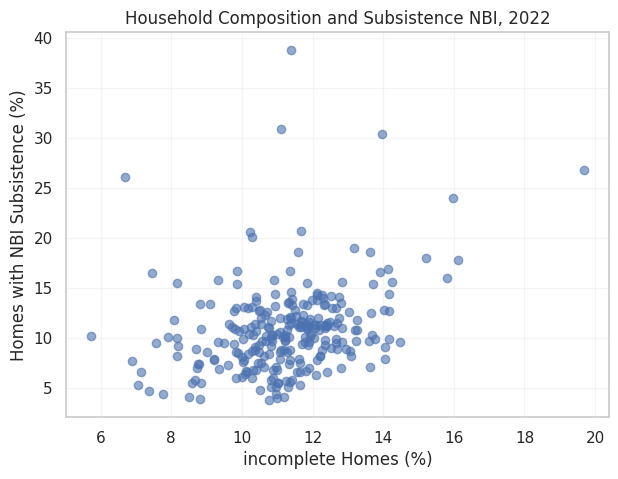

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    analysis_family["pct_incomp_home"],
    analysis_family["nbi_subsistence_pct"],
    alpha=0.6
)

plt.xlabel("incomplete Homes (%)")
plt.ylabel("Homes with NBI Subsistence (%)")
plt.title("Household Composition and Subsistence NBI, 2022")
plt.grid(alpha=0.2)

plt.show()

##LAND OWNERSHIP 2022

for this particular variable I am using data from The National Institute of Statitstics (population and housing data survey 2022). What I am interested in the percentages of land ownership in each of the districts. I am especially interested in seeing whether owning land reduces or increases these familie's subsistece capacity.

In [ ]:
landown= pd.read_excel("https://docs.google.com/uc?id=1Vl1isMiaQTvlwIu8yN4hk3X8dcXTEDDh&export=download",sheet_name="Cuadro 3",header=None)
landown.head(13)

,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Cuadro 3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Paraguay. Viviendas particulares ocupadas por ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Departamento y distrito,Total,Tenencia del terreno,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,Propio,Pagando a cuotas,Condominio,Fiscal o municipal,Alquilado,Cedido,Ocupado de hecho,Otro,No informado


In [ ]:
landown.shape

(293, 12)

In [ ]:
#again we need assign some meaningful names
#note that column "name" refers to the district name that we are going to change to "distric" so merge can be as easy as eating an apple"
owntype2022 = landown.iloc[12:, 1:12].copy()
owntype2022.columns = ["name","total_homes","owned","payin_install","Condo","municipal_fiscal","rented","given","ownedbyfact","other","notinformed"]
owntype2022.head(10)

,name,total_homes,owned,payin_install,Condo,municipal_fiscal,rented,given,ownedbyfact,other,notinformed
12,Asunción,129806,68398,1567,3090,14227,34126,2947,1263,23,4165
13,Concepción,56465,36412,2474,536,4361,3794,4118,2443,910,1417
14,Concepción,18969,11978,1148,144,1370,2367,952,581,88,341
15,Belén,3008,2098,28,16,393,98,188,119,19,49
16,Horqueta,11326,7671,703,169,858,406,614,545,50,310
17,Loreto,3805,2299,29,90,714,80,353,152,0,88
18,San Carlos del Apa,270,72,3,0,134,2,32,20,0,7
19,San Lázaro,3013,1686,167,15,418,333,114,156,31,93
20,Yby Yaú,5536,3764,297,32,20,258,371,222,349,223
21,Azote’y,1819,1289,31,9,16,70,95,64,191,54


In [ ]:
# first I restored owntype2022 from the original dataframe
owntype2022 = landown.iloc[12:, 1:12].copy()
owntype2022.columns = ["name","total_homes","owned","payin_install","Condo","municipal_fiscal","rented","given","ownedbyfact","other","notinformed"]
#now we can safely apply dropna over the pandas dataframe
owntype2022 = owntype2022.dropna(subset=["total_homes"]).copy()
# In order to avoid future conflicts I assigned the openpyxl sheet a different variable
landown_sheet = libro["Cuadro 3"]
# now, lets evaluate the "bold" format using our index and our original sheet
owntype2022["bold_name"] = [landown_sheet.cell(row=index + 1, column=2).font.bold == True for index in owntype2022.index]
owntype2022[["name", "total_homes", "bold_name"]].head(20)

,name,total_homes,bold_name
12,Asunción,129806,True
13,Concepción,56465,True
14,Concepción,18969,False
15,Belén,3008,False
16,Horqueta,11326,False
17,Loreto,3805,False
18,San Carlos del Apa,270,False
19,San Lázaro,3013,False
20,Yby Yaú,5536,False
21,Azote’y,1819,False


In [ ]:
#We want just districts and also change some colums names for merging
owntype2022["department"] = owntype2022["name"].where(owntype2022["bold_name"])
owntype2022["department"] = owntype2022["department"].ffill()
is_district = ~owntype2022["bold_name"]
is_asuncion = owntype2022["name"] == "Asunción"
land_districts = owntype2022.loc[is_district | is_asuncion].copy()
land_districts = land_districts.rename(columns={"name": "district"})
land_districts.head(10)

,district,total_homes,owned,payin_install,Condo,municipal_fiscal,rented,given,ownedbyfact,other,notinformed,bold_name,department
12,Asunción,129806,68398,1567,3090,14227,34126,2947,1263,23,4165,True,Asunción
14,Concepción,18969,11978,1148,144,1370,2367,952,581,88,341,False,Concepción
15,Belén,3008,2098,28,16,393,98,188,119,19,49,False,Concepción
16,Horqueta,11326,7671,703,169,858,406,614,545,50,310,False,Concepción
17,Loreto,3805,2299,29,90,714,80,353,152,0,88,False,Concepción
18,San Carlos del Apa,270,72,3,0,134,2,32,20,0,7,False,Concepción
19,San Lázaro,3013,1686,167,15,418,333,114,156,31,93,False,Concepción
20,Yby Yaú,5536,3764,297,32,20,258,371,222,349,223,False,Concepción
21,Azote’y,1819,1289,31,9,16,70,95,64,191,54,False,Concepción
22,Sargento José Félix López,1651,1149,11,7,87,55,96,122,40,84,False,Concepción


In [ ]:
#check for data type and mumeric values
land_columns = ["total_homes","owned","payin_install","Condo","municipal_fiscal","rented","given","ownedbyfact","other","notinformed"]
for column in ["total_homes"] + land_columns:land_districts[column] = pd.to_numeric(land_districts[column],errors="raise")
#print("Missing values:")
land_districts[["total_homes"] + land_columns].isna().sum()

,0
total_homes,0
total_homes,0
owned,0
payin_install,0
Condo,0
municipal_fiscal,0
rented,0
given,0
ownedbyfact,0
other,0


In [ ]:
#we also need to know the percentage of homes for our control variables so lets convert it to %
land_pct_columns = []
for column in land_columns:
    new_column = "pct_" + column
    land_districts[new_column] = (land_districts[column] / land_districts["total_homes"]) * 100
    land_pct_columns.append(new_column)

land_districts[["department", "district"] + land_pct_columns].head(10)

,department,district,pct_total_homes,pct_owned,pct_payin_install,pct_Condo,pct_municipal_fiscal,pct_rented,pct_given,pct_ownedbyfact,pct_other,pct_notinformed
12,Asunción,Asunción,100.0,52.692480,1.207186,2.380475,10.960202,26.290002,2.270311,0.972990,0.017719,3.208634
14,Concepción,Concepción,100.0,63.145132,6.051980,0.759133,7.222310,12.478254,5.018715,3.062892,0.463915,1.797670
15,Concepción,Belén,100.0,69.747340,0.930851,0.531915,13.065160,3.257979,6.250000,3.956117,0.631649,1.628989
16,Concepción,Horqueta,100.0,67.729119,6.206957,1.492142,7.575490,3.584672,5.421155,4.811937,0.441462,2.737065
17,Concepción,Loreto,100.0,60.420499,0.762155,2.365309,18.764783,2.102497,9.277267,3.994744,0.000000,2.312746
18,Concepción,San Carlos del Apa,100.0,26.666667,1.111111,0.000000,49.629630,0.740741,11.851852,7.407407,0.000000,2.592593
19,Concepción,San Lázaro,100.0,55.957517,5.542649,0.497843,13.873216,11.052108,3.783604,5.177564,1.028875,3.086625
20,Concepción,Yby Yaú,100.0,67.991329,5.364884,0.578035,0.361272,4.660405,6.701590,4.010116,6.304191,4.028179
21,Concepción,Azote’y,100.0,70.863112,1.704233,0.494777,0.879604,3.848268,5.222650,3.518417,10.500275,2.968664
22,Concepción,Sargento José Félix López,100.0,69.594185,0.666263,0.423985,5.269534,3.331314,5.814658,7.389461,2.422774,5.087826


In [ ]:
import unicodedata

def normalize_name(text):
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    text = " ".join(text.split())
    return text

land_districts["department_key"] = (land_districts["department"].apply(normalize_name))
land_districts["district_key"] = (land_districts["district"].apply(normalize_name))
land_districts.duplicated(subset=["department_key", "district_key"]).sum()
#This was particulatly important consideron that most of the data contained spanish caracters, so I had to normalize them

np.int64(0)

In [ ]:
land_districts.head(10)

,district,total_homes,owned,payin_install,Condo,municipal_fiscal,rented,given,ownedbyfact,other,...,pct_payin_install,pct_Condo,pct_municipal_fiscal,pct_rented,pct_given,pct_ownedbyfact,pct_other,pct_notinformed,department_key,district_key
12,Asunción,129806,68398,1567,3090,14227,34126,2947,1263,23,...,1.207186,2.380475,10.960202,26.290002,2.270311,0.972990,0.017719,3.208634,asuncion,asuncion
14,Concepción,18969,11978,1148,144,1370,2367,952,581,88,...,6.051980,0.759133,7.222310,12.478254,5.018715,3.062892,0.463915,1.797670,concepcion,concepcion
15,Belén,3008,2098,28,16,393,98,188,119,19,...,0.930851,0.531915,13.065160,3.257979,6.250000,3.956117,0.631649,1.628989,concepcion,belen
16,Horqueta,11326,7671,703,169,858,406,614,545,50,...,6.206957,1.492142,7.575490,3.584672,5.421155,4.811937,0.441462,2.737065,concepcion,horqueta
17,Loreto,3805,2299,29,90,714,80,353,152,0,...,0.762155,2.365309,18.764783,2.102497,9.277267,3.994744,0.000000,2.312746,concepcion,loreto
18,San Carlos del Apa,270,72,3,0,134,2,32,20,0,...,1.111111,0.000000,49.629630,0.740741,11.851852,7.407407,0.000000,2.592593,concepcion,san carlos del apa
19,San Lázaro,3013,1686,167,15,418,333,114,156,31,...,5.542649,0.497843,13.873216,11.052108,3.783604,5.177564,1.028875,3.086625,concepcion,san lazaro
20,Yby Yaú,5536,3764,297,32,20,258,371,222,349,...,5.364884,0.578035,0.361272,4.660405,6.701590,4.010116,6.304191,4.028179,concepcion,yby yau
21,Azote’y,1819,1289,31,9,16,70,95,64,191,...,1.704233,0.494777,0.879604,3.848268,5.222650,3.518417,10.500275,2.968664,concepcion,azote'y
22,Sargento José Félix López,1651,1149,11,7,87,55,96,122,40,...,0.666263,0.423985,5.269534,3.331314,5.814658,7.389461,2.422774,5.087826,concepcion,sargento jose felix lopez


#LIVESTOCK AND FARM TYPE DATA

For a quick recap, this study aims to see the association between household characteristics, land ownership, and agricultural or livestock activity and the nbi subsistence capacity varible. This second data comes from (datoabiertos.gov.py) where all the results of the last agrarian census 2022 are available. This following section is the iteration process of the last third (beacuse of the amount of junk, but instead of sociodemographics, I am aiming to get information about the type of farm (agricultural, livestock, forestry etc) I am just focusing on agricultural and livestok farms

In [ ]:
agrcensus2022.head(16)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,"Cuadro 1. Cantidad total de fincas, superficie...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Departamento / Distrito,Cantidad total de Fincas,Superficie total (ha),Tipo de actividad:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,Solo con actividad pecuaria,NaN,Solo plantaciones forestales,NaN,Con plantaciones forestales y actividad pecuaria,NaN,Solo con cultivos agrícolas,NaN,Con cultivos agricolas y actividad pecuaria,NaN,Con cultivos agricolas y plantaciones forestales,NaN,"Con cultivos agricolas, plantaciones forestale...",NaN
3,NaN,NaN,NaN,Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha),Cant. Fincas,Superficie (ha)
4,Total,291497,30401660.4529,73784,19223869.718,659,81716.723,2994,1238636.595,22758,1498315.525,181389,6189592.4229,1042,274638.649,8871,1894890.82
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Región Oriental,283052,13397506.4999,66943,4105260.965,655,76590.723,2945,856558.595,22268,1423750.225,180343,4832021.0229,1041,274635.149,8857,1828689.82
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,01. CONCEPCIÓN,16670,1521324.898,4966,960064.637,7,1588.5,62,169291.575,244,2946.6,11192,293623.636,6,994,193,92815.95
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
agrcensus2022.shape


(311, 17)

In [ ]:
#"Can" stands for Censo Agropecuario Nacional
#changed names in spanish to enlgish meaningful variables names
can2022 = agrcensus2022.iloc[6:].copy()
can2022.columns = ["name","farms_total","area_total_ha","farms_livestock_only","area_livestock_only_ha","farms_forestry_only","area_forestry_only_ha","farms_forestry_livestock","area_forestry_livestock_ha",
"farms_crops_only","area_crops_only_ha","farms_crops_livestock","area_crops_livestock_ha","farms_crops_forestry","area_crops_forestry_ha","farms_crops_forestry_livestock","area_crops_forestry_livestock_ha"]
can2022.head(5)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
6,Región Oriental,283052,13397506.4999,66943,4105260.965,655,76590.723,2945,856558.595,22268,1423750.225,180343,4832021.0229,1041,274635.149,8857,1828689.82
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,01. CONCEPCIÓN,16670,1521324.898,4966,960064.637,7,1588.5,62,169291.575,244,2946.6,11192,293623.636,6,994,193,92815.95
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,01. Concepción,1469,38210.259,397,11624.574,4,70.5,15,6527.0,20,331.15,1018,18950.035,2,38,13,669


In [ ]:
can2022.tail(5)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
306,01. Fuerte Olimpo,224,1474729.313,216,1346887.313,-,-,3,70753,-,-,5,57089,-,-,-,-
307,02. Puerto Casado,468,1633473.5,438,1441104.5,-,-,2,73657,4,2120,23,103925,-,-,1,12667
308,04. Bahía Negra,179,1366551.0,174,1301519.0,-,-,-,-,1,657,4,64375,-,-,-,-
309,05. Carmelo Peralta,186,398145.0,105,357383.0,-,-,1,633,-,-,76,2250.0,-,-,4,37879
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
len(can2022)
can2022 = can2022.dropna(how="all").copy()
can2022.tail(6)

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
304,17. ALTO PARAGUAY,1057,4872898.813,933,4446893.813,-,-,6,145043,5,2777,108,227639.0,-,-,5,50546
306,01. Fuerte Olimpo,224,1474729.313,216,1346887.313,-,-,3,70753,-,-,5,57089,-,-,-,-
307,02. Puerto Casado,468,1633473.5,438,1441104.5,-,-,2,73657,4,2120,23,103925,-,-,1,12667
308,04. Bahía Negra,179,1366551.0,174,1301519.0,-,-,-,-,1,657,4,64375,-,-,-,-
309,05. Carmelo Peralta,186,398145.0,105,357383.0,-,-,1,633,-,-,76,2250.0,-,-,4,37879
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
can2022.loc[can2022["farms_total"].isna(),["name", "farms_total"]]

,name,farms_total
200,01. Ciudad del Este,NaN
234,18. Ypané,NaN
291,05. Nanawa,NaN
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN


In [ ]:
can2022.loc[can2022["farms_total"].isna()]

,name,farms_total,area_total_ha,farms_livestock_only,area_livestock_only_ha,farms_forestry_only,area_forestry_only_ha,farms_forestry_livestock,area_forestry_livestock_ha,farms_crops_only,area_crops_only_ha,farms_crops_livestock,area_crops_livestock_ha,farms_crops_forestry,area_crops_forestry_ha,farms_crops_forestry_livestock,area_crops_forestry_livestock_ha
200,01. Ciudad del Este,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
234,18. Ypané,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
291,05. Nanawa,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
310,"El valor ""0"" corresponde a cifras menores a 0.5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
can2022["clean_name"] = (can2022["name"].str.replace(r"^\d+\.\s*", "", regex=True).str.strip())
can2022["is_department"] = can2022["clean_name"].str.isupper()

In [ ]:
can2022.loc[can2022["is_department"],["name", "clean_name"]]
can2022["is_department"].sum()

np.int64(18)

In [ ]:
has_numeric_prefix = can2022["name"].str.match(r"^\d+\.",na=False)
can2022["is_department"] = (can2022["clean_name"].str.isupper()& has_numeric_prefix)
can2022["is_department"].sum()


np.int64(17)

In [ ]:
display(can2022.loc[can2022["is_department"],["name", "clean_name"]])
print("Departamentos identificados:", can2022["is_department"].sum())

,name,clean_name
8,01. CONCEPCIÓN,CONCEPCIÓN
24,02. SAN PEDRO,SAN PEDRO
48,03. CORDILLERA,CORDILLERA
71,04. GUAIRÁ,GUAIRÁ
92,05. CAAGUAZÚ,CAAGUAZÚ
117,06. CAAZAPÁ,CAAZAPÁ
131,07. ITAPÚA,ITAPÚA
164,08. MISIONES,MISIONES
177,09. PARAGUARÍ,PARAGUARÍ
198,10. ALTO PARANÁ,ALTO PARANÁ


Departamentos identificados: 17


In [ ]:
can2022["department"] = can2022["clean_name"].where(can2022["is_department"])
can2022["department"] = can2022["department"].ffill()
can2022[["name", "department", "is_department"]].head(15)

,name,department,is_department
6,Región Oriental,NaN,False
8,01. CONCEPCIÓN,CONCEPCIÓN,True
10,01. Concepción,CONCEPCIÓN,False
11,02. Belén,CONCEPCIÓN,False
12,03. Horqueta,CONCEPCIÓN,False
13,04. Loreto,CONCEPCIÓN,False
14,05. San Carlos del Apa,CONCEPCIÓN,False
15,06. San Lázaro,CONCEPCIÓN,False
16,07. Yby Ya'ú,CONCEPCIÓN,False
17,08. Azote'y,CONCEPCIÓN,False


In [ ]:
is_district = has_numeric_prefix & ~can2022["is_department"]
can_districts = can2022.loc[is_district].copy()
can_districts = can_districts.rename(columns={"clean_name": "district"})
can_districts[["department", "district", "farms_total"] ].head(10)

,department,district,farms_total
10,CONCEPCIÓN,Concepción,1469
11,CONCEPCIÓN,Belén,1642
12,CONCEPCIÓN,Horqueta,5202
13,CONCEPCIÓN,Loreto,1944
14,CONCEPCIÓN,San Carlos del Apa,61
15,CONCEPCIÓN,San Lázaro,150
16,CONCEPCIÓN,Yby Ya'ú,1504
17,CONCEPCIÓN,Azote'y,643
18,CONCEPCIÓN,Sgto. José Félix López,544
19,CONCEPCIÓN,San Alfredo,332


In [ ]:
can_numeric_columns = [column for column in can_districts.columns if column.startswith("farms_") or column.startswith("area_")]
dash_counts = (can_districts[can_numeric_columns].eq("-").sum())

display(dash_counts)

,0
farms_total,2
area_total_ha,2
farms_livestock_only,2
area_livestock_only_ha,2
farms_forestry_only,112
area_forestry_only_ha,108
farms_forestry_livestock,25
area_forestry_livestock_ha,24
farms_crops_only,17
area_crops_only_ha,17


In [ ]:
print("Valores faltantes antes de tratar los guiones:")

display(
    can_districts[can_numeric_columns].isna().sum()
)

Valores faltantes antes de tratar los guiones:


,0
farms_total,3
area_total_ha,3
farms_livestock_only,3
area_livestock_only_ha,3
farms_forestry_only,3
area_forestry_only_ha,7
farms_forestry_livestock,3
area_forestry_livestock_ha,4
farms_crops_only,3
area_crops_only_ha,3


In [ ]:
can_before_conversion = can_districts.copy()

missing_report = pd.DataFrame({
    "original_blank": can_before_conversion[
        can_numeric_columns
    ].isna().sum(),

    "original_dash": can_before_conversion[
        can_numeric_columns
    ].eq("-").sum()
})

display(missing_report)

,original_blank,original_dash
farms_total,3,2
area_total_ha,3,2
farms_livestock_only,3,2
area_livestock_only_ha,3,2
farms_forestry_only,3,112
area_forestry_only_ha,7,108
farms_forestry_livestock,3,25
area_forestry_livestock_ha,4,24
farms_crops_only,3,17
area_crops_only_ha,3,17


In [ ]:
for column in can_numeric_columns:
    can_districts[column] = pd.to_numeric(
        can_districts[column].replace("-", float("nan")),
        errors="raise"
    )

display(can_districts[can_numeric_columns].dtypes)

,0
farms_total,float64
area_total_ha,float64
farms_livestock_only,float64
area_livestock_only_ha,float64
farms_forestry_only,float64
area_forestry_only_ha,float64
farms_forestry_livestock,float64
area_forestry_livestock_ha,float64
farms_crops_only,float64
area_crops_only_ha,float64


In [ ]:
missing_report["after_conversion"] = (
    can_districts[can_numeric_columns].isna().sum()
)

missing_report["expected_missing"] = (
    missing_report["original_blank"]
    + missing_report["original_dash"]
)

missing_report["matches"] = (
    missing_report["after_conversion"]
    == missing_report["expected_missing"]
)

display(missing_report)

,original_blank,original_dash,after_conversion,expected_missing,matches
farms_total,3,2,5,5,True
area_total_ha,3,2,5,5,True
farms_livestock_only,3,2,5,5,True
area_livestock_only_ha,3,2,5,5,True
farms_forestry_only,3,112,115,115,True
area_forestry_only_ha,7,108,115,115,True
farms_forestry_livestock,3,25,28,28,True
area_forestry_livestock_ha,4,24,28,28,True
farms_crops_only,3,17,20,20,True
area_crops_only_ha,3,17,20,20,True


In [ ]:
negative_counts = (
    can_districts[can_numeric_columns] < 0
).sum()

display(negative_counts)

,0
farms_total,0
area_total_ha,0
farms_livestock_only,0
area_livestock_only_ha,0
farms_forestry_only,0
area_forestry_only_ha,0
farms_forestry_livestock,0
area_forestry_livestock_ha,0
farms_crops_only,0
area_crops_only_ha,0


In [ ]:
farm_columns = [
    column for column in can_numeric_columns
    if column.startswith("farms_") and column != "farms_total"
]

for column in farm_columns:
    available = (
        can_districts[column].notna()
        & can_districts["farms_total"].notna()
    )

    exceeds_total = (
        can_districts.loc[available, column]
        > can_districts.loc[available, "farms_total"]
    )

    print(
        column,
        "| Comparaciones:", available.sum(),
        "| Superan el total:", exceeds_total.sum()
    )

farms_livestock_only | Comparaciones: 245 | Superan el total: 0
farms_forestry_only | Comparaciones: 135 | Superan el total: 0
farms_forestry_livestock | Comparaciones: 222 | Superan el total: 0
farms_crops_only | Comparaciones: 230 | Superan el total: 0
farms_crops_livestock | Comparaciones: 242 | Superan el total: 0
farms_crops_forestry | Comparaciones: 161 | Superan el total: 0
farms_crops_forestry_livestock | Comparaciones: 224 | Superan el total: 0


In [ ]:
can_districts.to_csv(
    "CAN_districts_2022.csv",
    index=False,
    encoding="utf-8-sig"
)

can_before_conversion.to_csv(
    "CAN_before_numeric_conversion.csv",
    index=False,
    encoding="utf-8-sig"
)

missing_report.to_csv(
    "CAN_missing_report.csv",
    index=True,
    index_label="variable",
    encoding="utf-8-sig"
)

In [ ]:
#import zipfile

#with zipfile.ZipFile(
    #"CAN_cleaning_files.zip",
   # "w",
    #zipfile.ZIP_DEFLATED
#) as package:

    #package.write("CAN_districts_2022.csv")
    #package.write("CAN_before_numeric_conversion.csv")
    #package.write("CAN_missing_report.csv")

#files.download("CAN_cleaning_files.zip")

## Standarized variables for merging

#DATA ANALYSIS


### MERGING ALL DATASETS (NBI, HOUSEHOLD, LAND, & CAN)
In this section, we consolidate our clean datasets to prepare the final master dataset for descriptive statistics, correlations, and regression analysis.



Descriptive Summary of the Integrated Variables

In [ ]:
import pandas as pd

# defining the keys
keys = ['department_key', 'district_key']
#and create a copy
df_master = analysis_family.copy()
#I am picking the colums aka my variables
nbi_and_family_cols = keys + [
    'department', 'district', 'total_homes', 'nbi_subsistence_pct',
    'pct_uni_home', 'pct_comp_home', 'pct_incomp_home', 'pct_ext_home', 'pct_compound_home']
# and then filter the dataset
df_master = df_master[[col for col in nbi_and_family_cols if col in df_master.columns]]

df_master.shape
df_master.head(3)

,department_key,district_key,department,district,total_homes,nbi_subsistence_pct,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home
0,asuncion,asuncion,Asunción,Asunción,133600,5.049401,18.242515,36.502994,10.967066,30.564371,3.723054
1,concepcion,concepcion,Concepción,Concepción,19196,8.204834,12.700563,39.419671,12.216087,33.147531,2.516149
2,concepcion,belen,Concepción,Belén,3015,11.310116,13.432836,45.572139,12.106136,27.860697,1.028192


In [ ]:
#to avoid madness lets first create a master df file based on the filterer demography
df_master = analysis_family[
    ['department_key', 'district_key', 'department', 'district', 'total_homes', 'nbi_subsistence_pct',
     'pct_uni_home', 'pct_comp_home', 'pct_incomp_home', 'pct_ext_home', 'pct_compound_home']].copy()

df_master.shape
df_master.head(3)

,department_key,district_key,department,district,total_homes,nbi_subsistence_pct,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home
0,asuncion,asuncion,Asunción,Asunción,133600,5.049401,18.242515,36.502994,10.967066,30.564371,3.723054
1,concepcion,concepcion,Concepción,Concepción,19196,8.204834,12.700563,39.419671,12.216087,33.147531,2.516149
2,concepcion,belen,Concepción,Belén,3015,11.310116,13.432836,45.572139,12.106136,27.860697,1.028192


In [ ]:
#2nd: columns we want to bring from housing census
land_cols_to_merge = keys + [
    'pct_owned', 'pct_payin_install', 'pct_Condo', 'pct_municipal_fiscal',
    'pct_rented', 'pct_given', 'pct_ownedbyfact'
    ]
# let copy only the relevant sections of land ownership
land_to_merge = land_districts[land_cols_to_merge].copy()
# Evitamos el MergeError eliminando columnas duplicadas previas en df_master si existen
overlap_cols = [col for col in land_cols_to_merge if col in df_master.columns and col not in keys]
if overlap_cols:
    df_master = df_master.drop(columns=overlap_cols)
#lets merge it in our df_master
df_master = df_master.merge(
    land_to_merge,
    on=keys,
    how='left'
)
display(df_master.head(3))

,department_key,district_key,department,district,total_homes,nbi_subsistence_pct,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,pct_compound_home,pct_owned,pct_payin_install,pct_Condo,pct_municipal_fiscal,pct_rented,pct_given,pct_ownedbyfact
0,asuncion,asuncion,Asunción,Asunción,133600,5.049401,18.242515,36.502994,10.967066,30.564371,3.723054,52.692480,1.207186,2.380475,10.960202,26.290002,2.270311,0.972990
1,concepcion,concepcion,Concepción,Concepción,19196,8.204834,12.700563,39.419671,12.216087,33.147531,2.516149,63.145132,6.051980,0.759133,7.222310,12.478254,5.018715,3.062892
2,concepcion,belen,Concepción,Belén,3015,11.310116,13.432836,45.572139,12.106136,27.860697,1.028192,69.747340,0.930851,0.531915,13.065160,3.257979,6.250000,3.956117


In [ ]:
# step 3: I apply the district maping to the national agrarian census just to ensure geographic consistency
can_matched = can_districts.copy()

# Ensure keys are normalized first since they don't exist yet in can_districts
can_matched['department_key'] = can_matched['department'].apply(normalize_name)
can_matched['district_key'] = can_matched['district'].apply(normalize_name)

can_matched['district_key_initial'] = can_matched['district_key']
# again the diccionarry to armonize the names that are different
name_map = [
    ["Alto Paraná", "Pdte. Franco", "Presidente Franco"],
    ["Amambay", "Cap. Bado", "Capitán Bado"],
    ["Boquerón", "Mcal. José Félix Estigarribia", "Mariscal José Félix Estigarribia"],
    ["Caaguazú", "Cnel. Oviedo", "Coronel Oviedo"],
    ["Caaguazú", "Mcal. Francisco Solano López", "Mariscal Francisco Solano López"],
    ["Concepción", "Sgto. José Félix López", "Sargento José Félix López"],
    ["Concepción", "Yby Ya'ú", "Yby Yaú"],
    ["Guairá", "Cnel. Martínez", "Coronel Martínez"],
    ["Itapúa", "Cnel. Bogado", "Coronel Bogado"],
    ["Itapúa", "Gral. Artigas", "General Artigas"],
    ["Itapúa", "Gral. Delgado", "General Delgado"],
    ["Ñeembucú", "Guazú Cuá", "Guazú-Cuá"],
    ["Paraguarí", "Tebicuarymi", "Tebicuary-mí"],
    ["Presidente Hayes", "Gral. José María Bruguez", "General José María Bruguez"],
    ["Presidente Hayes", "Tte. 1ro Manuel Irala Fernández", "Tte. 1° Manuel Irala Fernández"],
    ["Presidente Hayes", "Tte. Esteban Martínez", "Teniente Esteban Martínez"],
    ["San Pedro", "Gral. Elizardo Aquino", "General Elizardo Aquino"],
    ["San Pedro", "Gral. Francisco Isidoro Resquín", "General Francisco Isidoro Resquín"],
    ["San Pedro", "San Pedro del Ycuamandyjú", "San Pedro Del Ycuamandyyú"]
]
for dept_name, can_name, nbi_name in name_map:
    dep_key = normalize_name(dept_name)
    c_key = normalize_name(can_name)
    n_key = normalize_name(nbi_name)
    can_matched.loc[
        (can_matched['department_key'] == dep_key) & (can_matched['district_key_initial'] == c_key),
        'district_key'
    ] = n_key
len(name_map)

19

In [ ]:
# 4th: just making sure that we are working with number formats and calculatin the %activity over total farms
activities = ["crops_only", "livestock_only", "crops_livestock", "crops_forestry_livestock"]

for activity in activities:
    count_col = f"farms_{activity}"
    pct_col = f"pct_farms_{activity}"

    can_matched[count_col] = pd.to_numeric(can_matched[count_col], errors='coerce')
    can_matched['farms_total'] = pd.to_numeric(can_matched['farms_total'], errors='coerce')
    can_matched[pct_col] = (can_matched[count_col] / can_matched['farms_total']) * 100

# Since i am not using the whole dataset i am just picking the ones that I am interested in
can_cols_to_merge = keys + [
    'farms_total', 'pct_farms_crops_only', 'pct_farms_livestock_only',
    'pct_farms_crops_livestock', 'pct_farms_crops_forestry_livestock'
]
can_to_merge = can_matched[can_cols_to_merge].copy()
can_to_merge.head(5)

,department_key,district_key,farms_total,pct_farms_crops_only,pct_farms_livestock_only,pct_farms_crops_livestock,pct_farms_crops_forestry_livestock
10,concepcion,concepcion,1469.0,1.361470,27.025187,69.298843,0.884956
11,concepcion,belen,1642.0,0.730816,18.453106,79.354446,0.974421
12,concepcion,horqueta,5202.0,1.787774,26.509035,70.242215,1.211073
13,concepcion,loreto,1944.0,0.565844,13.271605,83.950617,2.109053
14,concepcion,san carlos del apa,61.0,NaN,98.360656,1.639344,NaN


In [ ]:
#5 yaayyyyyy lest merge everything
df_master = df_master.merge(
    can_to_merge,
    on=keys,
    how='left',
    suffixes=('', '_can')
)

print(f"¡Integración completada exitosamente! Dimensiones finales del dataset maestro: {df_master.shape}")
display(df_master.head(5))

¡Integración completada exitosamente! Dimensiones finales del dataset maestro: (263, 23)


,department_key,district_key,department,district,total_homes,nbi_subsistence_pct,pct_uni_home,pct_comp_home,pct_incomp_home,pct_ext_home,...,pct_Condo,pct_municipal_fiscal,pct_rented,pct_given,pct_ownedbyfact,farms_total,pct_farms_crops_only,pct_farms_livestock_only,pct_farms_crops_livestock,pct_farms_crops_forestry_livestock
0,asuncion,asuncion,Asunción,Asunción,133600,5.049401,18.242515,36.502994,10.967066,30.564371,...,2.380475,10.960202,26.290002,2.270311,0.972990,NaN,NaN,NaN,NaN,NaN
1,concepcion,concepcion,Concepción,Concepción,19196,8.204834,12.700563,39.419671,12.216087,33.147531,...,0.759133,7.222310,12.478254,5.018715,3.062892,1469.0,1.361470,27.025187,69.298843,0.884956
2,concepcion,belen,Concepción,Belén,3015,11.310116,13.432836,45.572139,12.106136,27.860697,...,0.531915,13.065160,3.257979,6.250000,3.956117,1642.0,0.730816,18.453106,79.354446,0.974421
3,concepcion,horqueta,Concepción,Horqueta,11355,10.937913,14.081902,45.830031,12.364597,26.587406,...,1.492142,7.575490,3.584672,5.421155,4.811937,5202.0,1.787774,26.509035,70.242215,1.211073
4,concepcion,loreto,Concepción,Loreto,3811,10.810811,12.280241,46.287064,13.251115,27.394385,...,2.365309,18.764783,2.102497,9.277267,3.994744,1944.0,0.565844,13.271605,83.950617,2.109053


In [ ]:
import pandas as pd

# Aseguramos que las variables del Censo Agropecuario existan en df_master antes de continuar

agricultural_cols = ['pct_farms_crops_only', 'pct_farms_livestock_only']
missing_cols = [col for col in agricultural_cols if col not in df_master.columns]
if missing_cols and 'can_to_merge' in globals():
  df_master = df_master.merge(
        can_to_merge[['department_key', 'district_key'] + missing_cols],
        on=['department_key', 'district_key'],
        how='left'
    )
  # Hacemos merge únicamente de las columnas faltantes desde can_to_merge usando las claves estandarizadas

In [ ]:
# Descriptive statistics of variables of interest
analysis_vars = [
    'nbi_subsistence_pct',
    'pct_uni_home', 'pct_comp_home',
    'pct_incomp_home',
    'pct_owned', 'pct_rented',
    'pct_farms_crops_only',
    'pct_farms_livestock_only'
]

df_master[analysis_vars].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
nbi_subsistence_pct,263.0,10.78,4.40,3.80,8.15,10.30,12.56,38.84
pct_uni_home,263.0,17.22,3.54,9.64,14.62,16.79,19.32,29.66
pct_comp_home,263.0,46.28,6.44,28.03,42.03,45.57,50.70,64.98
pct_incomp_home,263.0,11.23,1.72,5.72,10.30,11.28,12.17,19.68
pct_owned,263.0,60.09,12.71,9.71,54.27,61.90,68.57,81.49
pct_rented,263.0,6.08,5.75,0.34,2.39,3.85,7.44,33.09
pct_farms_crops_only,230.0,10.22,13.15,0.09,2.01,6.18,12.29,93.70
pct_farms_livestock_only,245.0,30.87,24.02,0.52,12.99,24.56,40.12,100.00


Descriptive statistics reveal substantial territorial variation in household deprivation and agricultural composition. Across 263 geographic units, the mean district-level NBI subsistence rate was 10.78%, ranging from 3.80% to 38.84%. Complete nuclear households represented the largest average share among the household categories reported. Agricultural composition was particularly heterogeneous: crop-only farms accounted for an average of 10.22% of establishments across 230 districts, while livestock-only farms represented 30.87% across 245 districts. These are unweighted district averages, and differences in available observations should be considered when comparing variables.

In [ ]:
import pandas as pd
dv = 'nbi_subsistence_pct'
ivs = ['pct_uni_home', 'pct_comp_home', 'pct_incomp_home','pct_owned', 'pct_rented',
    'pct_farms_crops_only', 'pct_farms_livestock_only']
correlation_results = []
for iv in ivs:
    # to avoid nule values I filtered the data jointly
    paired_data = df_master[[dv, iv]].dropna()
    n_obs = len(paired_data)

    if n_obs > 0:
        r_val = paired_data[dv].corr(paired_data[iv], method='pearson')
        rho_val = paired_data[dv].corr(paired_data[iv], method='spearman')

        correlation_results.append({
            'Variable': iv,
            'N': n_obs,
            "Pearson's r": r_val,
            "Spearman's rho": rho_val
        })
# Crear el DataFrame resumen
df_correlations = pd.DataFrame(correlation_results)
df_correlations.round(4)

,Variable,N,Pearson's r,Spearman's rho
0,pct_uni_home,263,0.2381,0.3596
1,pct_comp_home,263,-0.1698,-0.1606
2,pct_incomp_home,263,0.3123,0.3147
3,pct_owned,263,-0.2830,-0.1048
4,pct_rented,263,-0.4688,-0.5469
5,pct_farms_crops_only,230,-0.3227,-0.3020
6,pct_farms_livestock_only,245,0.3270,0.2174


Bivariate correlations showed that NBI subsistence was positively associated with single-person households, incomplete nuclear households, and livestock-only farm shares. Negative associations were observed for complete nuclear households, owned-land tenure, rented-land tenure, and crop-only farm shares. Rented-land tenure exhibited the largest association in absolute magnitude. Pearson and Spearman coefficients differed notably for owned-land tenure, indicating a need to inspect the underlying distribution and influential observations.

In [ ]:
import statsmodels.formula.api as smf

#making sure robustness
for col in ['pct_farms_crops_only', 'pct_farms_livestock_only']:
    if col not in df_master.columns and 'can_to_merge' in globals():
        df_master = df_master.merge(
            can_to_merge[['department_key', 'district_key', col]],
            on=['department_key', 'district_key'],
            how='left'
        )
# defining our OLS Model
regression_data = df_master.dropna(subset=[
    'nbi_subsistence_pct',
    'pct_uni_home', 'pct_incomp_home',
    'pct_owned', 'pct_rented',
    'pct_farms_crops_only', 'pct_farms_livestock_only'
])

print(f"Number of districts included in the regression: {len(regression_data)}")

ols_model = smf.ols(
    "nbi_subsistence_pct ~ pct_uni_home + pct_incomp_home + pct_owned + pct_rented + pct_farms_crops_only + pct_farms_livestock_only",
    data=regression_data
).fit(cov_type='HC3')

print(ols_model.summary())

Number of districts included in the regression: 230
                             OLS Regression Results                            
Dep. Variable:     nbi_subsistence_pct   R-squared:                       0.369
Model:                             OLS   Adj. R-squared:                  0.352
Method:                  Least Squares   F-statistic:                     21.26
Date:                 Wed, 28 Oct 2026   Prob (F-statistic):           1.09e-19
Time:                         20:30:36   Log-Likelihood:                -586.18
No. Observations:                  230   AIC:                             1186.
Df Residuals:                      223   BIC:                             1210.
Df Model:                            6                                         
Covariance Type:                   HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------

The multiple regression accounted for 36.9% of district-level variation in NBI subsistence (adjusted R2 = .352; n = 230). The percentage of incomplete nuclear households was positively associated with deprivation (B = 0.616, p = .013), while the owned and rented tenure shares were negatively associated with deprivation (B = −0.086, p = .020; B = −0.260, p < .001, respectively). Single-person households and the two agricultural indicators were not statistically significant at the .05 level. Although crop-only and livestock-only shares retained their respective negative and positive signs, their estimated associations were smaller than in the separate models. These changes are consistent with shared variation among agricultural, household, and tenure characteristics; they do not demonstrate mediation or establish which characteristics causally account for the relationships.

#DATA VISUALIZATION

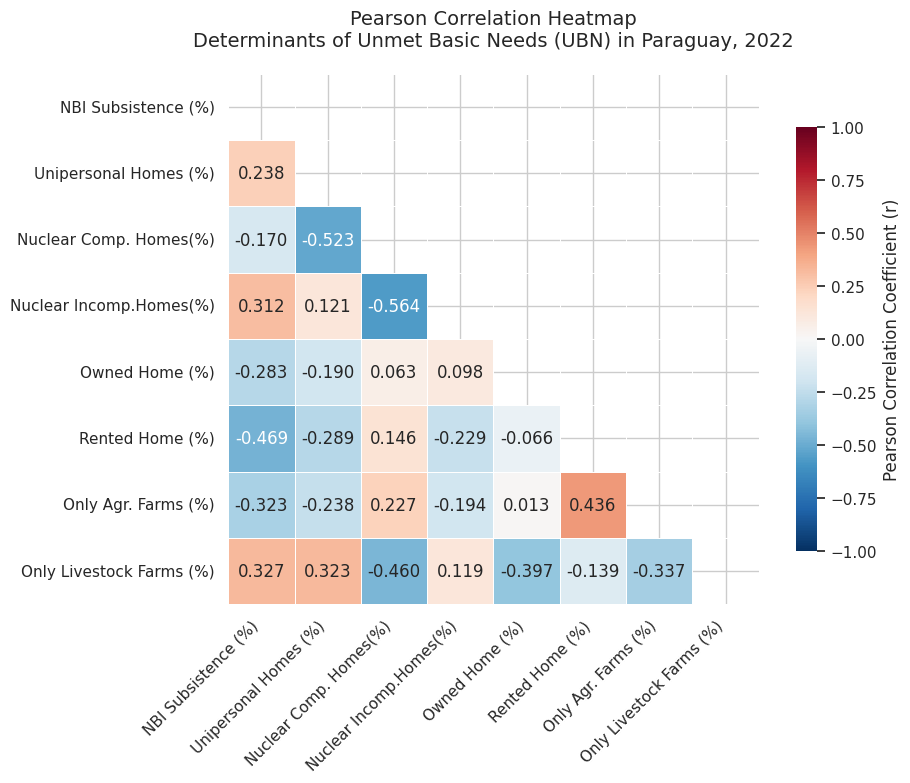

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# lets define the main variables first (gemini)
corr_vars = [
    'nbi_subsistence_pct',
    'pct_uni_home', 'pct_comp_home', 'pct_incomp_home',
    'pct_owned', 'pct_rented',
    'pct_farms_crops_only', 'pct_farms_livestock_only'
]

# the calculation itself
corr_matrix = df_master[corr_vars].corr(method='pearson')

# renaming so we have meaninfully explaing graphic
labels_dict = {
    'nbi_subsistence_pct': 'NBI Subsistence (%)',
    'pct_uni_home': 'Unipersonal Homes (%)',
    'pct_comp_home': 'Nuclear Comp. Homes(%)',
    'pct_incomp_home': 'Nuclear Incomp.Homes(%)',
    'pct_owned': 'Owned Home (%)',
    'pct_rented': 'Rented Home (%)',
    'pct_farms_crops_only': 'Only Agr. Farms (%)',
    'pct_farms_livestock_only': 'Only Livestock Farms (%)'
}

corr_matrix = corr_matrix.rename(index=labels_dict, columns=labels_dict)
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
#heat map (from reddit)
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)

plt.title("Pearson Correlation Heatmap\nDeterminants of Unmet Basic Needs (UBN) in Paraguay, 2022", fontsize=14, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# save
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

The Pearson correlation matrix indicates that district-level NBI subsistence is positively associated with incomplete nuclear households and livestock-only farm shares, and negatively associated with rented tenure and crop-only farm shares. Correlations among the explanatory variables suggest overlapping territorial patterns that should be considered when interpreting the adjusted regression. These relationships are descriptive, use pairwise available observations, and do not establish causal or household-level effects.

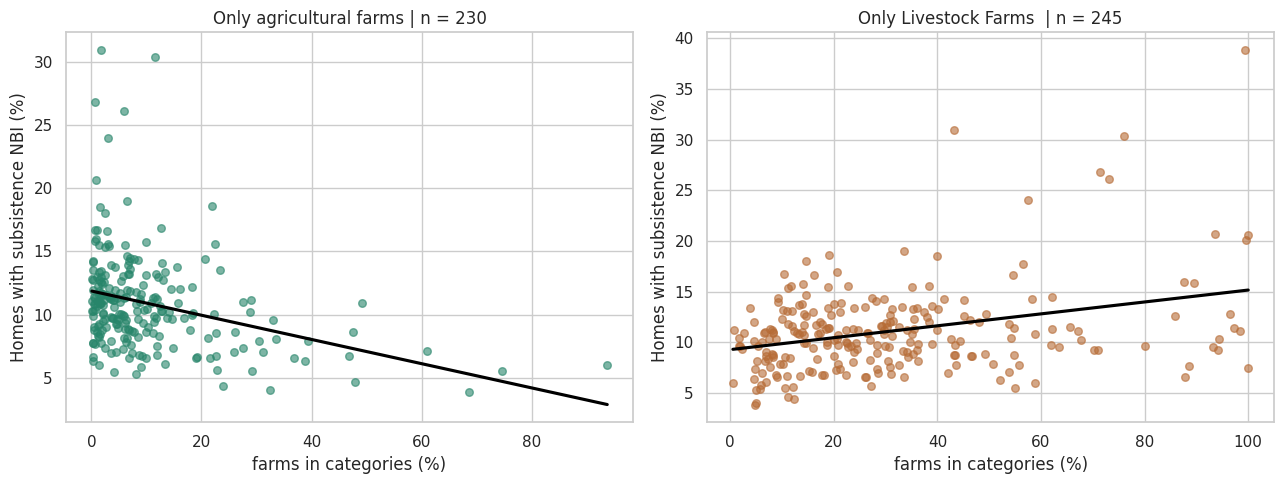

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Traemos las variables de participación agrícola desde can_to_merge hacia analysis_family de forma segura
for col in ["pct_farms_crops_only", "pct_farms_livestock_only"]:
    if col not in analysis_family.columns and 'can_to_merge' in globals():
        analysis_family = analysis_family.merge(
            can_to_merge[["department_key", "district_key", col]],
            on=["department_key", "district_key"],
            how="left"
        )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plots = [
    ("pct_farms_crops_only", "Only agricultural farms", "#27856A"),
    ("pct_farms_livestock_only", "Only Livestock Farms ", "#B66B35")
]

for ax, (variable, title, color) in zip(axes, plots):
    if variable in analysis_family.columns:
        data = analysis_family[
            [variable, "nbi_subsistence_pct"]
        ].dropna()

        sns.regplot(
            data=data,
            x=variable,
            y="nbi_subsistence_pct",
            ci=None,
            color=color,
            scatter_kws={"alpha": 0.6, "s": 30},
            line_kws={"color": "black"},
            ax=ax
        )

        ax.set_title(title + " | n = " + str(len(data)))
        ax.set_xlabel("farms in categories (%)")
        ax.set_ylabel("Homes with subsistence NBI (%)")
    else:
        ax.set_title(f"{title} (Variable No Encontrada)")

fig.tight_layout()
fig.savefig("scatter_productive_structure.png", dpi=300)
plt.show()

The figure shows contrasting bivariate associations between agricultural activity composition and district-level NBI in subsistence capacity. Among 230 districts, higher percentages of exclusively crop-producing farms are associated with lower deprivation rates (Pearson’s r = −0.323). Most observations are concentrated at relatively low crop-only shares, while relatively few districts occupy the upper end of the distribution. Among 245 districts, higher percentages of exclusively livestock-producing farms are associated with higher deprivation rates (r = 0.327). Both panels display substantial dispersion and several high-deprivation observations, indicating that agricultural composition alone does not adequately describe differences between districts. The fitted lines represent separate, unadjusted relationships estimated from different available samples. In the multiple regression, neither agricultural indicator was statistically significant at the .05 level after adjustment for household composition and tenure characteristics. These findings do not demonstrate causal effects or directly identify outcomes for family farms

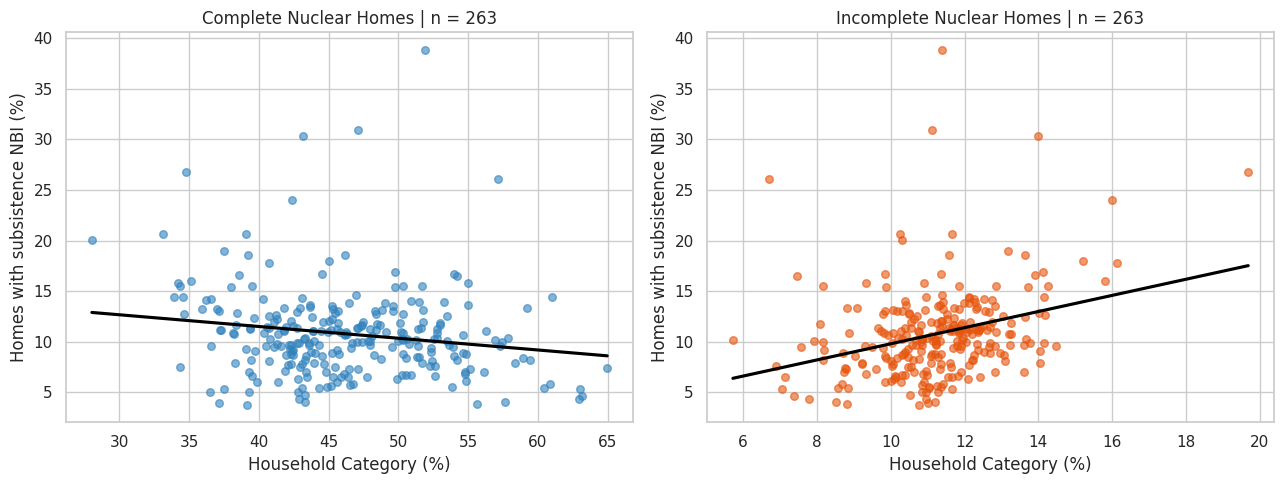

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# same as last one, i defined my variables
plots = [
    ("pct_comp_home", "Complete Nuclear Homes", "#3182bd"),
    ("pct_incomp_home", "Incomplete Nuclear Homes", "#e6550d")
]

for ax, (variable, title, color) in zip(axes, plots):
    if variable in analysis_family.columns:
        # filter null vaules
        data = analysis_family[
            [variable, "nbi_subsistence_pct"]
        ].dropna()

        sns.regplot(
            data=data,
            x=variable,
            y="nbi_subsistence_pct",
            ci=None,
            color=color,
            scatter_kws={"alpha": 0.6, "s": 30},
            line_kws={"color": "black"},
            ax=ax
        )

        ax.set_title(title + " | n = " + str(len(data)))
        ax.set_xlabel("Household Category (%)")
        ax.set_ylabel("Homes with subsistence NBI (%)")
    else:
        ax.set_title(f"{title} (Variable No Encontrada)")
#plot and save
fig.tight_layout()
fig.savefig("scatter_family_structure.png", dpi=300)
plt.show()

The figure compares household composition with district-level NBI in subsistence capacity across 263 geographic units. The left panel shows a weak negative association for complete nuclear households (Pearson’s r = −0.170): districts with higher shares of this household type tend to have slightly lower deprivation rates. The considerable dispersion around the fitted line indicates that this relationship alone captures little of the variation between districts. The right panel shows a clearer positive association for incomplete nuclear households (r = 0.312), although districts with similar household compositions still exhibit substantially different NBI rates. Several observations have unusually high deprivation values and warrant examination for influence. These are unadjusted district-level associations; they do not establish that household composition causes deprivation or describe the circumstances of individual households. In the multiple regression, the incomplete-nuclear-household share remained positively associated with NBI after adjustment for the other included variables (β = 0.616, p = .013).

In [ ]:
import plotly.express as px

household_labels = {
    "uni_home": "Unipersonal",
    "comp_home": "Nuclear Complete",
    "incomp_home": "Nuclear incomplete",
    "ext_home": "Extended",
    "compound_home": "Compounded"
}

household_totals = (
    analysis_family[family_columns]
    .sum()
    .rename_axis("variable")
    .reset_index(name="households")
)

household_totals["type"] = (
    household_totals["variable"].map(household_labels)
)

fig = px.treemap(
    household_totals,
    path=["type"],
    values="households",
    color="type",
    title="Type of homes across 250 municipalities in 2022"
)

fig.update_traces(
    texttemplate="%{label}<br>%{value:,.0f} hogares<br>%{percentRoot:.1%}",
    hovertemplate="%{label}<br>Hogares: %{value:,.0f}<extra></extra>"
)

fig.update_layout(
    margin=dict(t=60, l=10, r=10, b=10)
)

fig.show()
fig.write_html("treemap_household_types.html")

In [ ]:
%%capture
treemap_data = analysis_family.copy()

fig = px.treemap(
    treemap_data,
    path=["district"],
    values="nbi_subsistence_pct",
    color="nbi_subsistence_pct",
    color_continuous_scale="YlOrRd",
    custom_data=["department", "total_homes", "homesnbisubs"],
    title="District-level NBI subsistence rates, Paraguay, 2022"
)

fig.update_traces(
    texttemplate="%{label}<br>%{value:.1f}%",
    hovertemplate=(
        "<b>%{label}</b><br>"
        "Department: %{customdata[0]}<br>"
        "NBI subsistence: %{value:.2f}%<br>"
        "Total households: %{customdata[1]:,.0f}<br>"
        "Households with NBI subsistence: %{customdata[2]:,.0f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    height=750,
    coloraxis_colorbar_title="NBI subsistence (%)",
    margin=dict(t=70, l=10, r=10, b=10)
)

fig.show()
fig.write_html("district_nbi_subsistence_treemap.html")

In [ ]:
!apt-get install -y gdal-bin python3-gdal
!pip install geopandas mapclassify fiona pyproj shapely

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
gdal-bin is already the newest version (3.8.4+dfsg-3ubuntu3).
python3-gdal is already the newest version (3.8.4+dfsg-3ubuntu3).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
import zipfile
from pathlib import Path
boundary_zip = Path("/content/pry_admin_boundaries.gdb.zip")
with zipfile.ZipFile(boundary_zip) as package:
    package.extractall("/content/paraguay_boundaries")

In [ ]:
import geopandas as gpd

gdb_folders = list(
    Path("/content/paraguay_boundaries").rglob("*.gdb")
)

print("Geodatabases found:", gdb_folders)

assert len(gdb_folders) == 1, "Review the geodatabase folders before continuing."

gdb_path = str(gdb_folders[0])

display(gpd.list_layers(gdb_path))

Geodatabases found: [PosixPath('/content/paraguay_boundaries/pry_admin_boundaries.gdb')]


,name,geometry_type
0,pry_admin0,MultiPolygon
1,pry_admin1,MultiPolygon
2,pry_admin2,MultiPolygon
3,pry_admin3,MultiPolygon
4,pry_admin4,MultiPolygon
5,pry_admincapitals,Point
6,pry_adminpoints,Point


In [ ]:
districts_map = gpd.read_file(
    gdb_path,
    layer="pry_admin2"
)

print("Geographic features:", len(districts_map))
print("Coordinate reference system:", districts_map.crs)
print("Columns:", districts_map.columns.tolist())

display(
    districts_map.drop(columns="geometry").head(10)
)

Geographic features: 263
Coordinate reference system: EPSG:4326
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'area_sqkm', 'valid_on', 'valid_to', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'starea__', 'stlength__', 'geometry']


,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,area_sqkm,valid_on,valid_to,version,lang,lang1,lang2,lang3,starea__,stlength__
0,Asunción,None,None,None,PY0000,Asunción,None,None,None,PY00,...,128.693902,2026-07-29,NaT,v01,es,None,None,None,0.011535,0.560602
1,Concepción,None,None,None,PY0101,Concepción,None,None,None,PY01,...,444.691608,2026-07-29,NaT,v01,es,None,None,None,0.039277,1.382861
2,Belén,None,None,None,PY0102,Concepción,None,None,None,PY01,...,209.585456,2026-07-29,NaT,v01,es,None,None,None,0.018517,0.853762
3,Horqueta,None,None,None,PY0103,Concepción,None,None,None,PY01,...,1300.755325,2026-07-29,NaT,v01,es,None,None,None,0.114823,2.011733
4,Loreto,None,None,None,PY0104,Concepción,None,None,None,PY01,...,771.404333,2026-07-29,NaT,v01,es,None,None,None,0.068033,1.847367
5,San Carlos del Apa,None,None,None,PY0105,Concepción,None,None,None,PY01,...,1644.036372,2026-07-29,NaT,v01,es,None,None,None,0.144157,2.425632
6,San Lázaro,None,None,None,PY0106,Concepción,None,None,None,PY01,...,1188.297918,2026-07-29,NaT,v01,es,None,None,None,0.104103,2.065299
7,Yby Yaú,None,None,None,PY0107,Concepción,None,None,None,PY01,...,2191.061980,2026-07-29,NaT,v01,es,None,None,None,0.192976,2.681978
8,Azote'y,None,None,None,PY0108,Concepción,None,None,None,PY01,...,721.407289,2026-07-29,NaT,v01,es,None,None,None,0.063689,1.786283
9,Sargento José Félix López,None,None,None,PY0109,Concepción,None,None,None,PY01,...,2257.718037,2026-07-29,NaT,v01,es,None,None,None,0.198189,2.452753


In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd

# Define normalize_name to ensure keys match correctly
import unicodedata

def normalize_name(text):
    if not isinstance(text, str):
        return ""
    text = text.lower().strip()
    text = text.replace("’", "'")
    text = text.replace("‘", "'")
    text = unicodedata.normalize("NFKD", text)
    text = "".join(
        character for character in text
        if not unicodedata.combining(character)
    )
    text = " ".join(text.split())
    return text

# 1. Create standardized keys in your district shapefile 'districts_map'
districts_map["department_key"] = districts_map["adm1_name"].apply(normalize_name)
districts_map["district_key"] = districts_map["adm2_name"].apply(normalize_name)

# 2. Extract NBI subsistence rate data from your family dataset
nbi_map_data = analysis_family[["department_key", "district_key", "nbi_subsistence_pct"]].copy()

# 3. Merge the boundaries with the NBI data to create 'nbi_map'
nbi_map = districts_map.merge(
    nbi_map_data,
    on=["department_key", "district_key"],
    how="left"
)

# Use a projected coordinate system for the static map.
map_plot = nbi_map.to_crs(epsg=5880)

fig, ax = plt.subplots(figsize=(10, 11))

map_plot.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="#666666",
    linewidth=0.25,
    legend=True,
    legend_kwds={
        "label": "Households with NBI subsistence (%)",
        "shrink": 0.65
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "No data"
    },
    ax=ax
)

ax.set_title(
    "Households with NBI in Subsistence Capacity\n"
    "Paraguay, 2022",
    fontsize=15,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.04,
    "Data: INE, CNPV 2022, Table 4.\n"
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "263 matched units. Historical boundary equivalence not independently verified.",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(
    "paraguay_nbi_subsistence_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%%capture
import matplotlib.pyplot as plt

# --- 1. ADD HOUSEHOLD COMPOSITION TO THE MAP ---
# Select only the columns needed for this visualization.
household_map_data = analysis_family[
    ["department_key", "district_key", "pct_uni_home"]
].copy()

combined_map = nbi_map.merge(
    household_map_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

# Project the boundaries before placing symbols.
combined_map = combined_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
background_variable = "pct_uni_home"
circle_variable = "nbi_subsistence_pct"

background_label = "Single-person households (%)"
circle_label = "Households with NBI subsistence (%)"

background_cmap = "YlOrBr"
circle_color = "#2166AC"
size_factor = 8

title = (
    "Household Composition and NBI Subsistence\n"
    "Paraguay, 2022"
)

output_filename = "household_composition_nbi_map.png"

# --- 3. CREATE THE FIGURE ---
fig, ax = plt.subplots(figsize=(15, 12))

# Draw all boundaries in grey first.
# Districts without background data will remain grey.
combined_map.plot(
    color="#E0E0E0",
    edgecolor="grey",
    linewidth=0.2,
    ax=ax
)

background_data = combined_map.dropna(
    subset=[background_variable]
)

background_data.plot(
    column=background_variable,
    cmap=background_cmap,
    linewidth=0.2,
    edgecolor="grey",
    ax=ax,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": background_label
    }
)

# --- 4. ADD PROPORTIONAL CIRCLES ---
circle_data = combined_map.dropna(
    subset=[circle_variable]
).copy()

# Place points inside each district polygon.
circle_points = circle_data.geometry.representative_point()

ax.scatter(
    circle_points.x,
    circle_points.y,
    s=circle_data[circle_variable] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. CREATE THE CIRCLE LEGEND ---
example_values = [10, 20, 30]

legend_handles = []

for value in example_values:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title=circle_label,
    loc="lower left",
    frameon=True,
    labelspacing=1.5,
    borderpad=1.2
)

# --- 6. TITLE, SOURCE NOTE, AND EXPORT ---
ax.set_title(title, fontsize=18, pad=15)
ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: single-person households (%). "
    "Circle area: NBI subsistence rate (%).\n"
    "Grey districts: household composition unavailable in the selected analysis table.\n"
    "Data: INE, CNPV 2022. Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%%capture
import matplotlib.pyplot as plt

# --- 1. PREPARACIÓN DE DATOS DE TENENCIA DE TIERRA ---
# Extraemos 'pct_owned' de 'df_master' que es donde se consolidaron los datos de vivienda
land_map_data = df_master[
    ["department_key", "district_key", "pct_owned"]
].copy()

combined_land_map = nbi_map.merge(
    land_map_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

# Proyectar el mapa al sistema de coordenadas local para Paraguay (EPSG:5880)
combined_land_map = combined_land_map.to_crs(epsg=5880)

# --- 2. CONFIGURACIÓN DE VARIABLES ---
background_variable = "pct_owned"
circle_variable = "nbi_subsistence_pct"

background_label = "Viviendas con terreno propio (%)"
circle_label = "Hogares con NBI Subsistencia (%)"

background_cmap = "YlOrRd"
circle_color = "#2166AC"
size_factor = 8

title = (
    "Propiedad de la Tierra y NBI en Capacidad de Subsistencia\n"
    "Paraguay, 2022"
)

output_filename = "land_ownership_nbi_map.png"

# --- 3. CREACIÓN DE LA FIGURA ---
fig, ax = plt.subplots(figsize=(15, 12))

# Dibujar límites de fondo en gris para distritos sin datos
combined_land_map.plot(
    color="#E0E0E0",
    edgecolor="grey",
    linewidth=0.2,
    ax=ax
)

# Graficar el porcentaje de propiedad de la tierra como mapa coroplético de fondo
background_data = combined_land_map.dropna(
    subset=[background_variable]
)

background_data.plot(
    column=background_variable,
    cmap=background_cmap,
    linewidth=0.2,
    edgecolor="grey",
    ax=ax,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": background_label
    }
)

# --- 4. CÍRCULOS PROPORCIONALES PARA NBI SUBSISTENCIA ---
circle_data = combined_land_map.dropna(
    subset=[circle_variable]
).copy()

circle_points = circle_data.geometry.representative_point()

ax.scatter(
    circle_points.x,
    circle_points.y,
    s=circle_data[circle_variable] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. LEYENDA DE LOS CÍRCULOS DE NBI ---
example_values = [10, 20, 30]
legend_handles = []

for value in example_values:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )
    legend_handles.append(handle)

ax.legend(
    handles=legend_handles,
    title=circle_label,
    loc="lower left",
    frameon=True,
    labelspacing=1.5,
    borderpad=1.2
)

# --- 6. TÍTULO, NOTAS DE FUENTE Y EXPORTACIÓN ---
ax.set_title(title, fontsize=18, pad=15)
ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    f"Fondo coroplético: {background_label.lower()}. El área del círculo representa: {circle_label.lower()}.\n"
    "Distritos en gris: información de tenencia de tierra no disponible en la muestra seleccionada.\n"
    "Datos: INE, CNPV 2022. Límites: HDX COD-AB; valid_on: 2026-07-29.\n"
    "La equivalencia de límites históricos no ha sido verificada de forma independiente.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.12, 1, 1])

# Guardar la imagen con alta resolución
fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%%capture
import matplotlib.pyplot as plt

# --- 1. ADD THE AGRICULTURAL VARIABLE ---
agriculture_data = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_crops_only"
    ]
].copy()

agriculture_map = nbi_map.merge(
    agriculture_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

agriculture_map = agriculture_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
size_factor = 8
circle_color = "#2166AC"

output_filename = "nbi_crop_farms_map.png"

fig, ax = plt.subplots(figsize=(15, 12))

# --- 3. BACKGROUND: NBI SUBSISTENCE ---
agriculture_map.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="grey",
    linewidth=0.2,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": "Households with NBI subsistence (%)"
    },
    ax=ax
)

# --- 4. CIRCLES: EXCLUSIVELY CROP-PRODUCING FARMS ---
circle_data = agriculture_map.dropna(
    subset=["pct_farms_crops_only"]
).copy()

circle_points = circle_data.geometry.representative_point()

ax.scatter(
    circle_points.x,
    circle_points.y,
    s=circle_data["pct_farms_crops_only"] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. MARK DISTRICTS WITH MISSING AGRICULTURAL DATA ---
missing_data = agriculture_map.loc[
    agriculture_map["pct_farms_crops_only"].isna()
]

missing_points = missing_data.geometry.representative_point()

ax.scatter(
    missing_points.x,
    missing_points.y,
    marker="x",
    s=20,
    color="#444444",
    linewidth=0.8,
    label="Crop-farm percentage unavailable",
    zorder=4
)

# --- 6. SYMBOL LEGEND ---
legend_handles = []

for value in [5,10, 30, 60]:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

missing_handle = ax.scatter(
    [], [],
    marker="x",
    s=20,
    color="#444444",
    label="Data unavailable"
)

legend_handles.append(missing_handle)

ax.legend(
    handles=legend_handles,
    title="Exclusively crop-producing farms (%)",
    loc="lower left",
    labelspacing=1.5,
    borderpad=1.2,
    frameon=True
)

# --- 7. TITLE AND SOURCE NOTE ---
ax.set_title(
    "NBI Subsistence and Exclusively Crop-Producing Farms\n"
    "Paraguay, 2022",
    fontsize=18,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: households with NBI subsistence (%).\n"
    "Circle area: exclusively crop-producing farms as a percentage of all farms.\n"
    "Crosses indicate unavailable crop-farm percentages, not zero values.\n"
    "Data: INE, CNPV 2022; CAN 2022. "
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

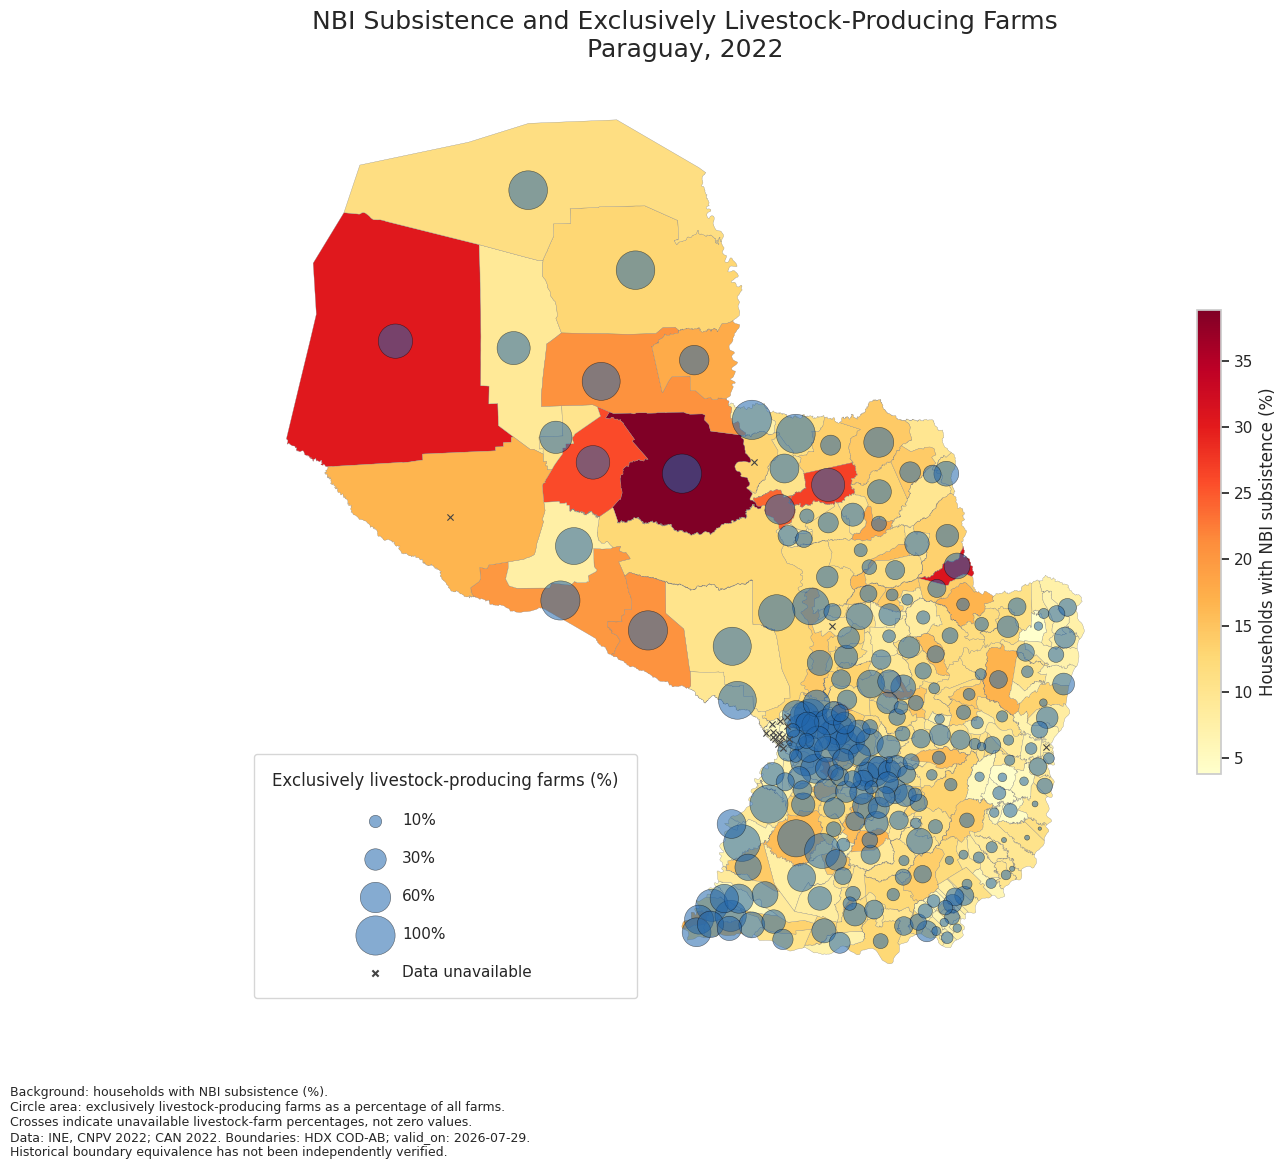

In [ ]:
import matplotlib.pyplot as plt

# --- 1. ADD THE LIVESTOCK VARIABLE ---
livestock_data = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_livestock_only"
    ]
].copy()

livestock_map = nbi_map.merge(
    livestock_data,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

livestock_map = livestock_map.to_crs(epsg=5880)

# --- 2. CONFIGURATION ---
size_factor = 8
circle_color = "#2166AC"
output_filename = "nbi_livestock_farms_map.png"

fig, ax = plt.subplots(figsize=(15, 12))

# --- 3. BACKGROUND: NBI SUBSISTENCE ---
livestock_map.plot(
    column="nbi_subsistence_pct",
    cmap="YlOrRd",
    edgecolor="grey",
    linewidth=0.2,
    legend=True,
    legend_kwds={
        "shrink": 0.5,
        "label": "Households with NBI subsistence (%)"
    },
    ax=ax
)

# --- 4. CIRCLES: EXCLUSIVELY LIVESTOCK-PRODUCING FARMS ---
circle_data = livestock_map.dropna(
    subset=["pct_farms_livestock_only"]
).copy()

circle_points = circle_data.geometry.representative_point()

# Draw larger circles first so smaller circles remain visible.
circle_data["point_x"] = circle_points.x
circle_data["point_y"] = circle_points.y

circle_data = circle_data.sort_values(
    "pct_farms_livestock_only",
    ascending=False
)

ax.scatter(
    circle_data["point_x"],
    circle_data["point_y"],
    s=circle_data["pct_farms_livestock_only"] * size_factor,
    color=circle_color,
    alpha=0.55,
    edgecolor="black",
    linewidth=0.4,
    zorder=3
)

# --- 5. MARK MISSING LIVESTOCK DATA ---
missing_data = livestock_map.loc[
    livestock_map["pct_farms_livestock_only"].isna()
]

missing_points = missing_data.geometry.representative_point()

ax.scatter(
    missing_points.x,
    missing_points.y,
    marker="x",
    s=20,
    color="#444444",
    linewidth=0.8,
    zorder=4
)

# --- 6. SYMBOL LEGEND ---
legend_handles = []

for value in [10, 30, 60, 100]:
    handle = ax.scatter(
        [],
        [],
        s=value * size_factor,
        color=circle_color,
        alpha=0.55,
        edgecolor="black",
        linewidth=0.4,
        label=f"{value}%"
    )

    legend_handles.append(handle)

legend_handles.append(
    ax.scatter(
        [], [],
        marker="x",
        s=20,
        color="#444444",
        label="Data unavailable"
    )
)

ax.legend(
    handles=legend_handles,
    title="Exclusively livestock-producing farms (%)",
    loc="lower left",
    labelspacing=1.5,
    borderpad=1.2,
    frameon=True
)

# --- 7. TITLE, NOTES, AND EXPORT ---
ax.set_title(
    "NBI Subsistence and Exclusively Livestock-Producing Farms\n"
    "Paraguay, 2022",
    fontsize=18,
    pad=15
)

ax.set_axis_off()

fig.text(
    0.05,
    0.03,
    "Background: households with NBI subsistence (%).\n"
    "Circle area: exclusively livestock-producing farms as a percentage of all farms.\n"
    "Crosses indicate unavailable livestock-farm percentages, not zero values.\n"
    "Data: INE, CNPV 2022; CAN 2022. "
    "Boundaries: HDX COD-AB; valid_on: 2026-07-29.\n"
    "Historical boundary equivalence has not been independently verified.",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.14, 1, 1])

fig.savefig(
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("Map districts:", len(agriculture_map))
print("Districts with crop-only percentages:",
    agriculture_map["pct_farms_crops_only"].notna().sum())
print("Districts shown with crosses:",
    agriculture_map["pct_farms_crops_only"].isna().sum())
print("Available crop-only percentages before the map join:",
    analysis_family["pct_farms_crops_only"].notna().sum())

Map districts: 263
Districts with crop-only percentages: 230
Districts shown with crosses: 33
Available crop-only percentages before the map join: 230


In [ ]:
display(
    agriculture_map.loc[
        agriculture_map["pct_farms_crops_only"].isna(),
        ["adm1_name", "adm2_name"]
    ].sort_values(["adm1_name", "adm2_name"])
)

,adm1_name,adm2_name
262,Alto Paraguay,Carmelo Peralta
259,Alto Paraguay,Fuerte Olimpo
166,Alto Paraná,Ciudad del Este
0,Asunción,Asunción
258,Boquerón,Boquerón
93,Caaguazú,Simón Bolivar
189,Central,Capiatá
190,Central,Fernando de la Mora
194,Central,Lambaré
195,Central,Limpio


In [ ]:
print(
    "Available percentages on the map:",
    agriculture_map["pct_farms_crops_only"].notna().sum()
)

print(
    "Crosses on the map:",
    agriculture_map["pct_farms_crops_only"].isna().sum()
)

Available percentages on the map: 230
Crosses on the map: 33


In [444]:
%%capture

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
import json

# Forzar el renderizador optimizado para evitar bloqueos de seguridad en Google Colab
pio.renderers.default = 'colab'

# --- 1. JOIN THE PRODUCTIVE VARIABLES TO THE BOUNDARIES ---
productive_variables = analysis_family[
    [
        "department_key",
        "district_key",
        "pct_farms_crops_only",
        "pct_farms_livestock_only"
    ]
].copy()

interactive_productive = nbi_map.merge(
    productive_variables,
    on=["department_key", "district_key"],
    how="left",
    validate="one_to_one"
)

# Calculate interior points in projected coordinates for placing symbols.
projected = interactive_productive.to_crs(epsg=5880)
points = projected.geometry.representative_point().to_crs(epsg=4326)

interactive_productive["longitude"] = points.x
interactive_productive["latitude"] = points.y

# Convert any non-serializable Timestamp columns to strings to prevent JSON serialization errors
for col in interactive_productive.columns:
    if interactive_productive[col].dtype == "datetime64[ns]" or "datetime" in str(interactive_productive[col].dtype):
        interactive_productive[col] = interactive_productive[col].dt.strftime("%Y-%m-%d")
    elif hasattr(interactive_productive[col], "dt"):
        interactive_productive[col] = interactive_productive[col].astype(str)

# Also explicitly stringify known boundary date columns just in case
for date_col in ["valid_on", "valid_to"]:
    if date_col in interactive_productive.columns:
        interactive_productive[date_col] = interactive_productive[date_col].astype(str)

# Convert GeoDataFrame geometry to GeoJSON for Plotly
geojson_dict = json.loads(interactive_productive.to_json())

# Create the base interactive choropleth map using Plotly Express
fig_base = px.choropleth_map(
    interactive_productive,
    geojson=geojson_dict,
    locations=interactive_productive.index,
    color="nbi_subsistence_pct",
    color_continuous_scale="YlOrRd",
    map_style="open-street-map",
    zoom=5.5,
    center={"lat": -23.4, "lon": -58.4},
    opacity=0.6,
    labels={"nbi_subsistence_pct": "NBI Subsistence (%)"},
    custom_data=["adm2_name", "adm1_name", "nbi_subsistence_pct"]
)

# Update hover template of the base choropleth map
fig_base.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Department: %{customdata[1]}<br>"
        "NBI subsistence: %{customdata[2]:.2f}%<br>"
        "<extra></extra>"
    )
)

# Create our figure structure from the base map
productive_fig = go.Figure(fig_base)

# --- 2. ADD AGRICULTURAL AND LIVESTOCK CIRCLES ---
layers = [
    (
        "pct_farms_crops_only",
        "Exclusively crop-producing farms",
        "#2166AC"
    ),
    (
        "pct_farms_livestock_only",
        "Exclusively livestock-producing farms",
        "#238B45"
    )
]

for variable, label, color in layers:
    available = interactive_productive.dropna(subset=[variable])

    productive_fig.add_trace(
        go.Scattermap(
            lon=available["longitude"],
            lat=available["latitude"],
            mode="markers",
            name=label,
            visible=False,
            customdata=available[
                ["adm2_name", "adm1_name", variable]
            ].to_numpy(),
            marker=dict(
                size=available[variable],
                sizemode="area",
                sizeref=2 * 100 / (35 ** 2),
                color=color,
                opacity=0.75
            ),
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Department: %{customdata[1]}<br>"
                + label + ": %{customdata[2]:.2f}%"
                "<extra></extra>"
            )
        )
    )

# --- 3. ADD LAYER BUTTONS ---
# Trace order: 0 (NBI background), 1 (agricultural circles), 2 (livestock circles)
productive_fig.update_layout(
    title="NBI Subsistence and Farm Composition — Paraguay, 2022",
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            x=0,
            y=1.08,
            buttons=[
                dict(
                    label="NBI only",
                    method="update",
                    args=[{"visible": [True, False, False]}]
                ),
                dict(
                    label="Crop-only farms",
                    method="update",
                    args=[{"visible": [True, True, False]}]
                ),
                dict(
                    label="Livestock-only farms",
                    method="update",
                    args=[{"visible": [True, False, True]}]
                )
            ]
        )
    ],
    margin=dict(t=130, b=80),
    annotations=[
        dict(
            text=(
                "Background: NBI subsistence (%). "
                "Circle area: farms in the selected category (%).<br>"
                "Missing percentages are omitted; no circle does not establish zero.<br>"
                "Data: CNPV/CAN 2022. HDX boundaries valid_on: 2026-07-29; "
                "historical equivalence not verified."
            ),
            x=0,
            y=-0.06,
            xref="paper",
            yref="paper",
            showarrow=False,
            align="left",
            font=dict(size=10)
        )
    ]
)

productive_fig.show(config={"scrollZoom": True})

#CONCLUSION

This study examined how agricultural activity composition, household structure, and land tenure relate to district-level deprivation in Paraguay using data from the 2022 population and agricultural censuses. The findings reveal substantial territorial variation in the percentage of households experiencing unmet basic needs in subsistence capacity.The bivariate analysis identified lower deprivation rates in districts with higher shares of exclusively crop-producing farms and higher deprivation rates in districts with larger shares of exclusively livestock-producing farms. However, neither agricultural indicator remained statistically significant after adjustment for the household composition and tenure variables included in the model. This suggests that the initial agricultural associations overlap with broader territorial characteristics. It does not establish that agricultural composition is irrelevant, nor does it identify the mechanisms underlying these relationships.

In the adjusted model, incomplete nuclear households were positively associated with deprivation, while owned and rented tenure shares were negatively associated with deprivation. Together, the six predictors accounted for approximately 36.9% of the observed variation across the 230 districts analyzed. These associations should not be interpreted as evidence that particular household structures cause deprivation or that tenure arrangements independently protect against it.The study contributes a reproducible approach to linking census sources and examining agricultural and social conditions at the district level. Its findings support considering agricultural development alongside household circumstances and territorial opportunities. Policy implications remain provisional: the results do not justify promoting one farming activity over another without examining land access, employment, infrastructure, and institutional support.

Further research should clarify agricultural reporting symbols, assess the consequences of missing observations, and examine influential cases and spatial dependence. Incorporating measures of rurality, land concentration, farm size, and employment would strengthen the analysis. Ultimately, understanding deprivation in Paraguay requires attention both to what territories produce and to how their residents gain access to the resources and opportunities needed to sustain their livelihoods.